## 1. Compréhension du problème

### Contexte

Je travaille sur un problème de **catégorisation automatique de produits** pour une plateforme e-commerce.  
Dans ce type de système, une mauvaise catégorisation n’est pas anodine : lorsqu’un produit est mal classé, il devient **difficile à trouver**, voire **totalement invisible** pour les utilisateurs qui naviguent dans les bonnes catégories. À grande échelle, cela dégrade l’**expérience utilisateur** et peut avoir un **impact direct sur les ventes**.

L’enjeu est donc à la fois **business** et **technique** : améliorer la qualité de la catégorisation pour rendre le catalogue plus cohérent, plus navigable et plus performant.

---

### Objectif

Mon objectif est de concevoir un **algorithme de classification automatique** capable d’assigner chaque produit à sa **catégorie feuille correcte** (`category_id`), en utilisant uniquement les informations produit disponibles.

---

### Contraintes et cadre du problème

Le guideline impose un cadre clair que je dois respecter :

- **Features autorisées**
  - `title`
  - `description`
  - `brand`
  - `color`

- **Variable cible**
  - `category_id` (catégorie feuille)

- **Feature interdite à l’entraînement**
  - `category_path`

Même si `category_path` contient une information très riche, je ne peux l’utiliser que pour **l’analyse exploratoire** ou l’**évaluation**, jamais comme entrée du modèle.

---

### Première réflexion : données structurées vs non structurées

En parcourant le guideline, une première question s’est immédiatement imposée à moi :  
**à quel type de données ai-je affaire ?**

Je distingue rapidement deux grandes familles :

- **Données structurées**
  - `product_id`
  - `brand`
  - `color`
  - `category_id` (uniquement comme label)

- **Données non structurées**
  - `title`
  - `description`

Cette distinction est essentielle, car elle conditionne la manière dont je vais représenter l’information et construire mon modèle.

---

### Comment exploiter ces deux types de données ?

Une fois cette distinction faite, une autre question s’est posée naturellement :  
**comment combiner efficacement des données structurées et non structurées ?**

L’approche la plus évidente et la plus flexible qui m’est venue à l’esprit est la suivante :
- traiter séparément les données structurées et les données textuelles,
- apprendre un **embedding spécifique** pour chaque type de données,
- puis **fusionner** ces représentations avant la phase de classification.

Cette approche me semble particulièrement intéressante car elle est :
- modulaire,
- extensible,
- et adaptable à différentes architectures de modèles.

Je reviendrai plus tard sur les détails techniques de cette fusion.

---

### Flat ou hierarchical product categorization ?

Une autre question importante concerne la **structure des catégories**.  
Les catalogues e-commerce reposent généralement sur des **taxonomies hiérarchiques**, ce qui m’amène à hésiter entre deux stratégies :

- **Flat classification**
  - prédiction directe de la catégorie feuille,
  - souvent plus performante en termes de métriques,
  - mais qui ignore les relations parent–enfant.

- **Hierarchical classification**
  - prédiction niveau par niveau dans la taxonomie,
  - garantit la cohérence taxonomique,
  - mais peut souffrir de propagation d’erreurs.

Comme le rappelle la littérature :

> *E-commerce catalogs typically employ hierarchical structures, leading to two main strategies: flat classifiers, which assign items directly to leaf nodes, and hierarchical classifiers, which traverse taxonomies level by level. Flat classifiers sometimes outperform but ignore parent–child consistency, while hierarchical methods enforce taxonomic coherence.*

À ce stade, je choisis de **ne pas trancher immédiatement**. Le choix final dépendra du EDA que je vais éffectuer, des résultats expérimentaux. Il est également envisageable d’explorer les deux approches.

---

### La classification de produits n’est pas une simple classification de texte

Même si le problème peut sembler proche de la **classification de texte classique**, je réalise rapidement qu’il s’agit d’un cas plus complexe :
- le nombre de classes doit probablement être élevé,
- la structure est très souvent hiérarchique,
- les textes produits peuvent être souvent courts, bruités et hétérogènes.

Autrement dit, la classification de produits est en general une **classification de texte à grande échelle**, pour laquelle de nombreux modèles deep learning standards ne sont pas directement adaptés.

---

### Unimodal ou multimodal ?

En analysant les données disponibles, je constate qu’elles sont exclusivement **textuelles** (au sens large) :
- texte libre (`title`, `description`)
- attributs catégoriels (`brand`, `color`)

Il n’y a ni image, ni signal multimédia.  
Je suis donc clairement face à un problème **unimodal**.

---

### Métriques d’évaluation

Du point de vue métier, le problème est un problème de **classification multi-classes**.  
La métrique la plus pertinente me semble être le **F1-score** (possibilité de faire des ajustement sur cette métrique), car elle offre un bon compromis entre :
- la précision, essentielle pour éviter les mauvaises catégorisations (produits affichés dans une catégorie incorrecte, impactant l’expérience utilisateur et la navigation),
- le rappel, crucial pour ne pas manquer les bons produits dans une catégorie donnée (perte de visibilité et de conversion).

En complément, la **matrice de confusion** me permettra d’analyser finement les erreurs, en particulier les confusions entre catégories proches.

---

### Architecture conceptuelle proposée

À partir de cette compréhension progressive du problème, j’ai esquissé une **architecture conceptuelle** que je souhaite garder volontairement simple et évolutive.  
L’objectif n’est pas encore l’optimisation, mais d’avoir une **vision claire du pipeline global**.

<p align="center">
  <img src="archi.png" alt="Architecture du modèle" width="600"/>
</p>

Certaines étapes intermédiaires sont volontairement omises afin de ne pas surcharger le schéma.

---

### Données disponibles

Le guideline met à disposition deux jeux de données :
- `trainset.csv`
- `testset.csv`

Ils contiennent :
- `product_id`
- `category_id` (uniquement dans le train)
- `category_path`
- `title`, `description`, `brand`, `color`

Conformément aux consignes, les prédictions devront être réalisées **uniquement** à partir des features autorisées.

---

### Une réflexion sur l’ajout de données externes

Je me suis également demandé s’il serait pertinent d’enrichir les données avec des sources externes (autres plateformes e-commerce).  
Même si cela pourrait améliorer la généralisation du modèle, cette piste n’est pas explorée ici, principalement pour des raisons de **temps**, de **coût en ressources** et de **cadre de projet**. Mais pour un réel project cette possibilité n'est pas à exclure surtout si les données actuelles sont modestes.

---

À ce stade, je considère que le problème est suffisamment bien compris pour entamer sereinement la **phase d’analyse exploratoire des données**.


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from collections import Counter
import re
import textwrap
from sklearn.preprocessing import LabelEncoder, OrdinalEncoder
import torch
from torch import nn
from torch.utils.data import Dataset, DataLoader
from collections import Counter
from torch.nn.utils.rnn import pad_sequence
from sklearn.metrics import f1_score, confusion_matrix, ConfusionMatrixDisplay
import torch 
from torch import nn
from transformers import AutoTokenizer, AutoModel
import torch.nn.functional as F
from sklearn.linear_model import LogisticRegression
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.pipeline import make_pipeline
from spacy.lang.fr.stop_words import STOP_WORDS as fr_stop
from spacy.lang.en.stop_words import STOP_WORDS as en_stop
import re
from scipy import sparse
from sklearn.preprocessing import StandardScaler
from sklearn.base import BaseEstimator, TransformerMixin
import math 
from tqdm.notebook import tqdm
from collections import defaultdict
import os
import json
import traceback
import random
from torch.utils.data import DataLoader, random_split
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import f1_score, accuracy_score
os.environ["TOKENIZERS_PARALLELISM"] = "false"

# Configuration
plt.rcParams['figure.figsize'] = (14, 8)
plt.rcParams['font.size'] = 12
sns.set_style("whitegrid")

## 2. Analyse exploratoire des données (EDA)

Avant toute modélisation, je dois m’assurer que :

- les données sont correctement chargées,

- les colonnes correspondent au guideline,

- les tailles train/test sont cohérentes.

Cela me permet aussi d’avoir une première intuition sur la structure du dataset.

In [2]:
def load_datasets(train_path, test_path):
    print("Loading datasets...")

    try:
        trainset = pd.read_csv(train_path)
        testset = pd.read_csv(test_path)
    except Exception as e:
        raise RuntimeError(f"Error loading datasets: {e}")

    print("Datasets loaded successfully.")

    print(f"Training set loaded: {trainset.shape[0]} rows, {trainset.shape[1]} columns")
    print(f"Test set loaded: {testset.shape[0]} rows, {testset.shape[1]} columns")
    
    return trainset, testset

In [3]:
trainset, testset = load_datasets(
    train_path="trainset.csv",
    test_path="testset.csv"
)

Loading datasets...
Datasets loaded successfully.
Training set loaded: 30520 rows, 7 columns
Test set loaded: 7631 rows, 7 columns


In [4]:
trainset.head()

,product_id,category_id,category_path,title,description,brand,color
0,86caaf89-8156-42f4-9fd8-10e08a325ee1,0a04a732,e3a03b90/72a77496/cfcafc53/b4ad0c8c/c0887815/c...,Lindy 37771 Cable d'antenne Premium M/M 1m,"Prises: standard coaxial, or, pour un meilleur...",LINDY,Gris
1,a723802b-72b1-4f0e-b618-93776190bfc9,1ae3c505,e3a03b90/72a77496/cfcafc53/17b1bfd8/1ae3c505,Camescope Camera Video 4K 30MP Caméscope avec ...,NaN,CZ,NaN
2,c2bfc33d-b52a-4ba1-b7ee-cdf3b4e52625,1a6f4f23,e3a03b90/107f27db/f59b9a2e/2050ad6d/1a6f4f23,Caso WineComfort 38 Cave à vin design pour max...,Für perfekt temperierte Weine sorgt von nun a...,Caso,Acier Inoxydable
3,7ee2b19e-3e74-47e8-a91d-ab6311c3a44c,f5856233,e3a03b90/e056c138/ec34940b/6ceb5201/1fd7323c/8...,CLAIREFONTAINE Lot de 2 Ramettes 125 Feuilles ...,2 X Clairefontaine 1855 Ramette de 125 feuille...,Clairefontaine,NaN
4,a00557c5-1934-4223-bdee-3c74710aa881,c7049963,e3a03b90/79f03259/55eb19f3/ae8739c9/cbced5e2/7...,Sac Banane Bumbumbag Sundae Transparent Vert,"Sac banane Bumbumbag pour homme et femme, en m...",BUMBUMBAG,Jaune


In [5]:
trainset.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 30520 entries, 0 to 30519
Data columns (total 7 columns):
 #   Column         Non-Null Count  Dtype 
---  ------         --------------  ----- 
 0   product_id     30520 non-null  object
 1   category_id    30520 non-null  object
 2   category_path  30520 non-null  object
 3   title          30520 non-null  object
 4   description    22351 non-null  object
 5   brand          29662 non-null  object
 6   color          14720 non-null  object
dtypes: object(7)
memory usage: 1.6+ MB


In [6]:
trainset.isna().sum()

product_id           0
category_id          0
category_path        0
title                0
description       8169
brand              858
color            15800
dtype: int64

In [7]:
testset.head()

,product_id,category_id,category_path,title,description,brand,color
0,20cbaaa9-f662-4309-a614-9c074cf6bd1a,f30a5ca5,e3a03b90/72a77496/cfcafc53/1929dc6a/da8dd254/2...,vhbw Batterie Compatible avec Philips Fidelio ...,vhbw - the clever way - Batterie de rechange d...,vhbw,non pertinent / batterie interne
1,e81b3d42-261f-4a19-9e48-d7a6b9142f79,e4037400,e3a03b90/72a77496/cfcafc53/b4ad0c8c/e4037400,TV LED 4K 126 cm 50PUS7505,Une esthétique soignée et un excellent son. Té...,Philips,Noir
2,a972f069-a2ef-4e89-bcbb-7628cf33a6e4,747b1103,e3a03b90/5c547035/92ae13aa/a1e34353/1ec4a51d/7...,Royal Catering RCZK-SET5 Machine à Barbe à Pap...,Indispensable pour tous les amoureux de la bar...,Royal Catering,Blanc
3,4b3b7ab3-4381-41d5-86b7-c7c6d7f0b567,a79ffcab,e3a03b90/5c547035/92ae13aa/a1e34353/1ec4a51d/a...,shangji Cuvette de Fabricant de Pop-Corn Pliab...,NaN,shangji,Green
4,de1695f6-3f51-4ab7-a9ca-967915ac8738,7cc22399,e3a03b90/ee159b1d/600c2de1/7cc22399,"MAGIX Samplitude Music Studio 2022, Everything...",NaN,Magix,NaN


In [8]:
testset.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7631 entries, 0 to 7630
Data columns (total 7 columns):
 #   Column         Non-Null Count  Dtype 
---  ------         --------------  ----- 
 0   product_id     7631 non-null   object
 1   category_id    7631 non-null   object
 2   category_path  7631 non-null   object
 3   title          7631 non-null   object
 4   description    5646 non-null   object
 5   brand          7410 non-null   object
 6   color          3755 non-null   object
dtypes: object(7)
memory usage: 417.4+ KB


In [9]:
testset.isna().sum()

product_id          0
category_id         0
category_path       0
title               0
description      1985
brand             221
color            3876
dtype: int64

Le jeu d’entraînement comprend **30 520 produits** et le jeu de test **7 631 produits**.

Les deux jeux présentent une structure parfaitement identique, avec **7 colonnes** chacune, ce qui assure une cohérence appréciable pour l’analyse et la modélisation. La taille du dataset est réaliste : ni trop restreinte, ni trop volumineuse, ce qui est un atout compte tenu des ressources à ma disposition.

On observe cependant la présence de **valeurs manquantes** dans les  colonnes `description`; `brand`, `color`. Ce point n’est pas anodin : la gestion des données manquantes peut avoir un impact significatif sur la performance du modèle, le choix des modèles et la stratégie de fusion des features.  
Il est donc essentiel d’identifier précisément quelles variables sont les plus touchées et de déterminer si l’absence d’information est structurelle ou simplement marginale. Ce diagnostic guidera les étapes suivantes du pipeline.

Note: par absence structurelle; je veux savoir si l'absence est liée à la nature même du produit ou du système, pas à une erreur. Effet, je sais que dans la réalité certains produits n'ont pas de couleur pertinente pour le metier. Et par absence marginal, je veux savoir si c'est accidentelle ou exceptionnelle.

Proportion de valeurs manquantes par feature dans le jeu d'entraînement:
color            0.517693
description      0.267661
brand            0.028113
category_path    0.000000
category_id      0.000000
product_id       0.000000
title            0.000000
dtype: float64


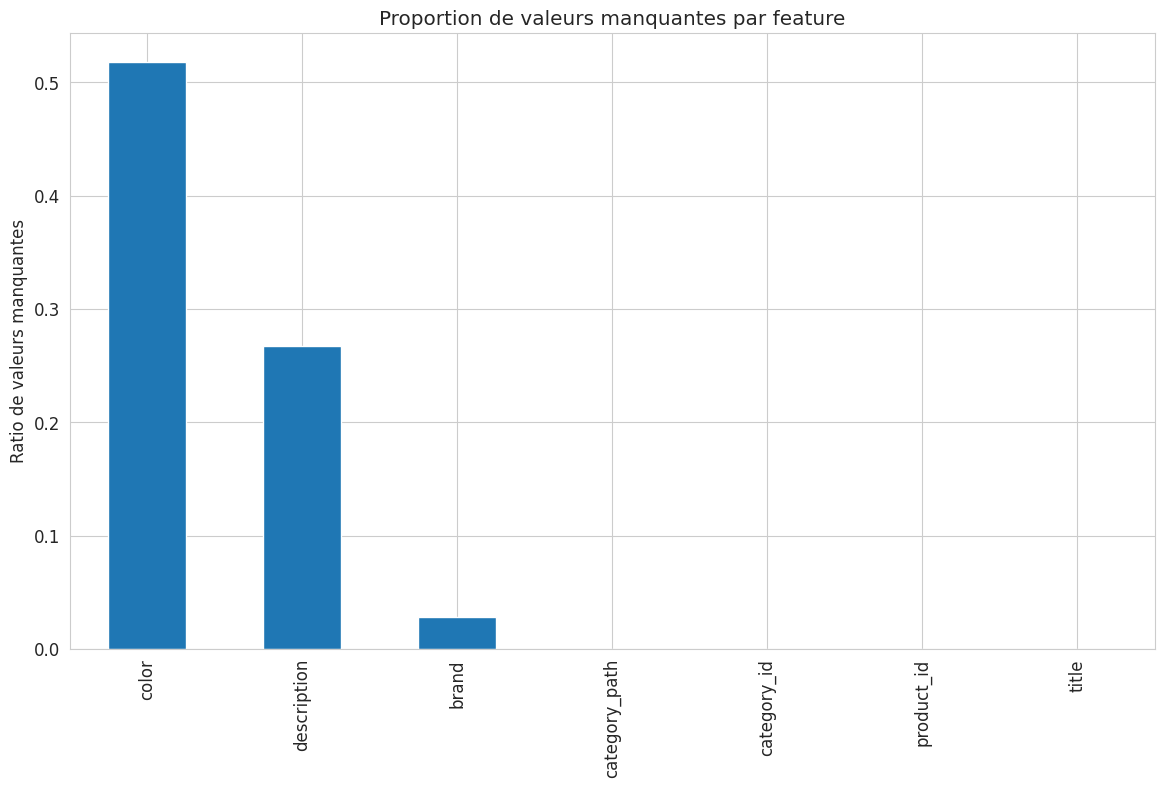

In [10]:
missing_ratio = trainset.isna().mean().sort_values(ascending=False)
print("Proportion de valeurs manquantes par feature dans le jeu d'entraînement:")
print(missing_ratio)
missing_ratio.plot(
    kind="bar",
    title="Proportion de valeurs manquantes par feature"
)
plt.ylabel("Ratio de valeurs manquantes")
plt.show()

En explorant les données, quelques constats s'imposent rapidement. La colonne `title` se distingue par sa fiabilité: aucune valeur manquante, c'est le socle sur lequel le modèle pourra toujours s'appuyer. À l'inverse, la colonne `description` révèle une réalité plus nuancée: près d'un quart des produits en sont dépourvus. Cela implique que, même si cette feature est riche en information, le modèle devra être capable de s'en passer dans de nombreux cas.

La situation est encore plus délicate pour la variable `color`. Plus d'un produit sur deux n'indique aucune couleur; il faudra l'utiliser avec discernement (à noter que certains que cette abscence peut être structurelle). Enfin, la colonne `brand` présente un taux de valeurs manquantes relativement faible, mais non négligeable.

Face à cette hétérogénéité, il devient évident que l'architecture du modèle devra être pensée pour résister à l'absence partielle d'information. La robustesse aux features manquantes n'est pas un luxe, mais une nécessité pour garantir des prédictions fiables sur l'ensemble du catalogue.

*Suivant les precedentes explications, je ne vais pas supprimer une ligne à cause d'une description manquante, je vais remplacer les valeurs manquantes par un token explicite ("no_color ou unknown") et sûrement accorder plus de poids au titre et brand qu'à color si cela peut améliorer le modèle*

In [11]:
missing_brand_ratio = trainset["brand"].isna().mean()
missing_color_ratio = trainset["color"].isna().mean()

print(f"Taux de valeurs manquantes - brand : {missing_brand_ratio:.2%}")
print(f"Taux de valeurs manquantes - color : {missing_color_ratio:.2%}")

Taux de valeurs manquantes - brand : 2.81%
Taux de valeurs manquantes - color : 51.77%


In [12]:
# Création d'un indicateur binaire de présence
trainset["has_color"] = trainset["color"].notna()
trainset["has_brand"] = trainset["brand"].notna()

In [13]:
color_by_category = (
    trainset
    .groupby("category_id")["has_color"]
    .mean()
    .sort_values()
)

color_by_category.describe()

count    100.000000
mean       0.434925
std        0.294354
min        0.000000
25%        0.170714
50%        0.482079
75%        0.684344
max        0.920716
Name: has_color, dtype: float64

In [14]:
color_by_category.head(20) # Note: au total il ya 100 catégories

category_id
06ff5497    0.000000
1cab2f83    0.000000
1b99320d    0.000000
40e0fb5b    0.000000
3bc90ab4    0.000000
734ca10c    0.000000
715851fc    0.000000
70b12b6d    0.000000
ff79c721    0.000000
d0fe004a    0.000000
b1d981cd    0.000000
a3b1cb6c    0.000000
da04a809    0.002247
23fe7583    0.003460
7cc22399    0.003610
58c6d31b    0.005362
ade715dc    0.009615
336ed296    0.013072
d9f533b4    0.013921
aa3cb014    0.019608
Name: has_color, dtype: float64

In [15]:
color_by_category.tail(20)

category_id
0184ed7a    0.735385
77ae620b    0.735795
73d6d79a    0.739414
471b89a6    0.759259
6a4f150b    0.762803
230ea963    0.771277
5b52c1fd    0.772251
6bf135c9    0.777778
48907735    0.781081
1a6f4f23    0.792916
3191f37d    0.801047
6f96699c    0.803665
83b06bc1    0.831135
4d1efc0c    0.837912
9671e881    0.845506
0c60b2a9    0.855978
7ed6a93e    0.870317
0089ad4b    0.885475
4999472d    0.887363
e5ae58c9    0.920716
Name: has_color, dtype: float64

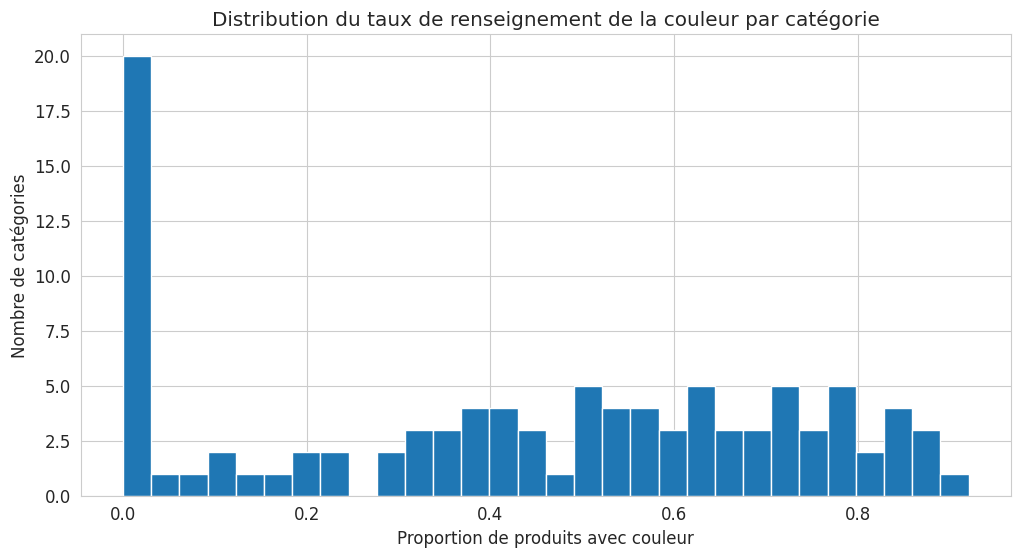

In [16]:
plt.figure(figsize=(12, 6))
plt.hist(color_by_category, bins=30)
plt.title("Distribution du taux de renseignement de la couleur par catégorie")
plt.xlabel("Proportion de produits avec couleur")
plt.ylabel("Nombre de catégories")
plt.show()

En moyenne, seulement **43 %** des produits disposent d’une couleur renseignée, mais la **variance élevée** (écart-type = 0,29) révèle une **forte hétérogénéité entre les catégories**. Certaines catégories (environ 20) affichent même un taux de complétion nul : aucun produit, ou presque, n’y possède de couleur indiquée. Il paraît peu crédible que tous les vendeurs aient « oublié » de renseigner cette information ou qu’il s’agisse d’un simple bruit aléatoire. Cela suggère que la couleur n’est tout simplement **pas une caractéristique pertinente pour ces produits dans ces catégories**.

On est donc face à une **absence structurelle** : l’information manque non pas par négligence, mais parce qu’elle n’a pas de sens pour certains types de produits.

In [17]:
# Sélection de quelques catégories sans couleur (proportion nulle)
categories_sans_couleur = color_by_category[color_by_category == 0].index[:5]

for cat_id in categories_sans_couleur:
    print(f"\nCatégorie sans couleur : {cat_id}")
    display(
        trainset[trainset["category_id"] == cat_id][
            ["product_id", "title", "brand", "color", "description"]
        ].head(3)
    )


Catégorie sans couleur : 06ff5497


,product_id,title,brand,color,description
116,99c95f46-eec0-43b4-8bc4-3d6406656539,Photo & Graphic Designer 6,Magix,NaN,Amazon.fr MAGIX Photo & Graphic Designer 6 est...
713,888d0ef5-419b-4431-b7ff-2d3e2a0e29e1,Photo Objects 10 000,HEMERA,NaN,Vaste collection d'images Photo-Objects et d'o...
983,8e71bbbc-36dc-4c71-8855-43e39006a9cd,Spyder3 Pro,datacolor,NaN,Amazon.fr Spyder3Pro™ répond aux besoins ...



Catégorie sans couleur : 1cab2f83


,product_id,title,brand,color,description
37,c011e9f8-53dd-429c-982a-c1dd08a2b57d,Der große Navigo 3D Globus [import allemand],United Soft Media Verlag GmbH,NaN,NaN
112,b81371fa-9b37-42cb-be1b-7fed474ba398,PC CAD Pro,Micro Application,NaN,NaN
131,84cecdc4-4fcb-4e4e-aec2-d795aa6b9ebf,Architecte 3D 21 | Jardin et Exterieur | PC | ...,Avanquest/Punch!,NaN,NaN



Catégorie sans couleur : 1b99320d


,product_id,title,brand,color,description
239,28efaeaf-5679-4331-8212-ddbf6e0fc97a,Dragon pour Mac 5 - Standard [Mac Download],Nuance,NaN,Dragon pour Mac dope la productivité des utili...
287,32483869-5f27-4bde-9705-80181cd09a03,Dragon NaturallySpeaking Home v12,Nuance,NaN,"Nuance 12.0 Home, Dragon NaturallySpeaking. Mé..."
704,39e96743-6891-48b7-88e2-fedf505a8bb6,Dragon NaturallySpeaking Basic v12,Nuance Communications,NaN,DRAGON NATURALLYSPEAKING BASIC V12



Catégorie sans couleur : 40e0fb5b


,product_id,title,brand,color,description
94,4f167c0b-9123-4922-ad38-2eb02f57be5e,Systran Personal V5 Pack Français 6 langues (f...,Mysoft,NaN,Description Pack Promotionnel incluant so...
1058,5263c421-4d61-4ca9-aa18-0d4b596edf9a,Power Translator 16 Express Deutsch-Französisc...,Avanquest,NaN,NaN
1158,42d358ae-1b20-4962-b2c9-5219f03ae92a,Personal Transl.2008 Adv,Editions Profil,NaN,Personal Translator est le logiciel de traduct...



Catégorie sans couleur : 3bc90ab4


,product_id,title,brand,color,description
110,ece6744b-38d6-453b-ae5c-f903385b784c,Talk Now Flamand,EuroTalk,NaN,<p><b>EuroTalk</b> vous présente la version 20...
335,10eff030-5d6d-4439-ad88-886c692c1386,Talk Now! turc,Talk Now!,NaN,Il y a quelques éléments que vous aurez besoin...
506,61735d6f-5301-48dd-a6bf-aa79ac8e20bc,"Talk to Me 7.0 Englisch, Komplettausgabe 1+2 [...",Auralog,NaN,NaN


Pour toutes les catégories listées (par exemple : `06ff5497`, `1cab2f83`, `3bc90ab4`, etc.), les produits dépourvus de couleur correspondent principalement à des logiciels, des contenus numériques ou des ressources éducatives (tels que des logiciels de graphisme, dictionnaires, outils de traduction, solutions de reconnaissance vocale, etc.).

Dans ce contexte, la notion de « couleur » n’a tout simplement pas de sens : il ne s’agit pas d’objets physiques dotés d’une couleur distinctive, mais de produits immatériels ou de services logiciels.  
Cela confirme que, pour certaines catégories, la variable `color` doit être ignorée ou explicitement considérée dans le cas général (on fera cette supposition) comme absente par conception, afin d’éviter d’introduire du bruit ou des biais dans la modélisation.

In [18]:
brand_by_category = (
    trainset
    .groupby("category_id")["has_brand"]
    .mean()
    .sort_values()
)

brand_by_category.describe()

count    100.000000
mean       0.964203
std        0.059687
min        0.530612
25%        0.954309
50%        0.983624
75%        0.993964
max        1.000000
Name: has_brand, dtype: float64

In [19]:
brand_by_category.head(20)

category_id
0b3dec20    0.530612
999632b0    0.760563
336ed296    0.823529
64f675d6    0.840909
09bacde9    0.846667
1ddc63f9    0.863014
b6a1c35a    0.906780
1778b75f    0.913043
d9f533b4    0.914153
1b99320d    0.922652
9661d5ad    0.930070
c7049963    0.932692
9c01b569    0.934524
d2f80618    0.937500
7cc22399    0.938628
f59b9a2e    0.940000
70b12b6d    0.940439
d0fe004a    0.941860
da04a809    0.943820
5b52c1fd    0.945026
Name: has_brand, dtype: float64

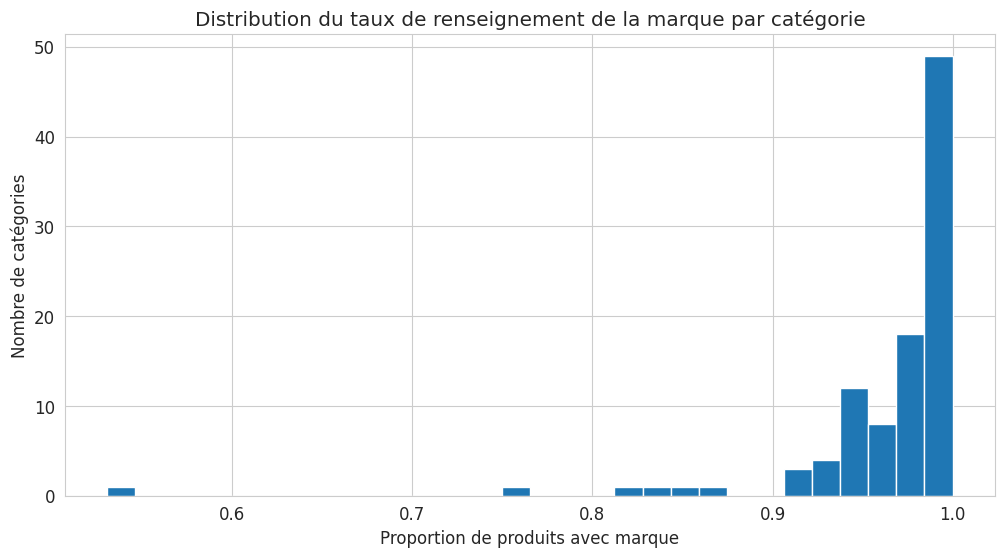

In [20]:
plt.figure(figsize=(12, 6))
plt.hist(brand_by_category, bins=30)
plt.title("Distribution du taux de renseignement de la marque par catégorie")
plt.xlabel("Proportion de produits avec marque")
plt.ylabel("Nombre de catégories")
plt.show()

La variable `brand` présente un taux de complétion très élevé : **96 %** des produits disposent d’une marque renseignée. La variance entre catégories est très faible : dans quasiment toutes les catégories, la présence d’une marque est la norme. Même dans les catégories les moins bien renseignées, plus d’un produit sur deux possède une marque ; aucune catégorie n’approche un taux nul.

Cela exclut pourrait  donc l’hypothèse d’une **absence structurelle** de la marque : la non-présence d’une marque n’est pas liée à la nature du produit ou à une logique métier.  
L’absence de `brand` semble plutôt relever de **cas marginaux** : erreurs de saisie, oublis ponctuels ou situations exceptionnelles, sans lien avec une typologie particulière de produits.

### Analyse de la variable cible : `category_id`

Comprendre la variable cible est une étape cruciale dans tout problème de classification multi-classes, en particulier dans le contexte du e-commerce où la taxonomie produit est souvent complexe.

Les questions clés à que je souhaite explorer sont :

- **La distribution des catégories est-elle équilibrée ou déséquilibrée ?**
- **Observe-t-on une "long tail" caractéristique des catalogues e-commerce, avec quelques catégories très fréquentes et une majorité de catégories rares ?**

Répondre à ces questions permet d’anticiper les principaux défis du modèle : gestion du déséquilibre, robustesse face aux classes rares, et choix d’une stratégie de classification adaptée (flat vs hierarchical).

In [21]:
num_categories = trainset["category_id"].nunique()
print(f"Nombre de catégories uniques dans le jeu d'entraînement: {num_categories}")

Nombre de catégories uniques dans le jeu d'entraînement: 100


In [22]:
category_counts = trainset["category_id"].value_counts()
print("Statistiques descriptives des occurrences par catégorie:")
category_counts.describe()

Statistiques descriptives des occurrences par catégorie:


count    100.000000
mean     305.200000
std      102.882693
min       66.000000
25%      273.750000
50%      351.000000
75%      370.250000
max      466.000000
Name: count, dtype: float64

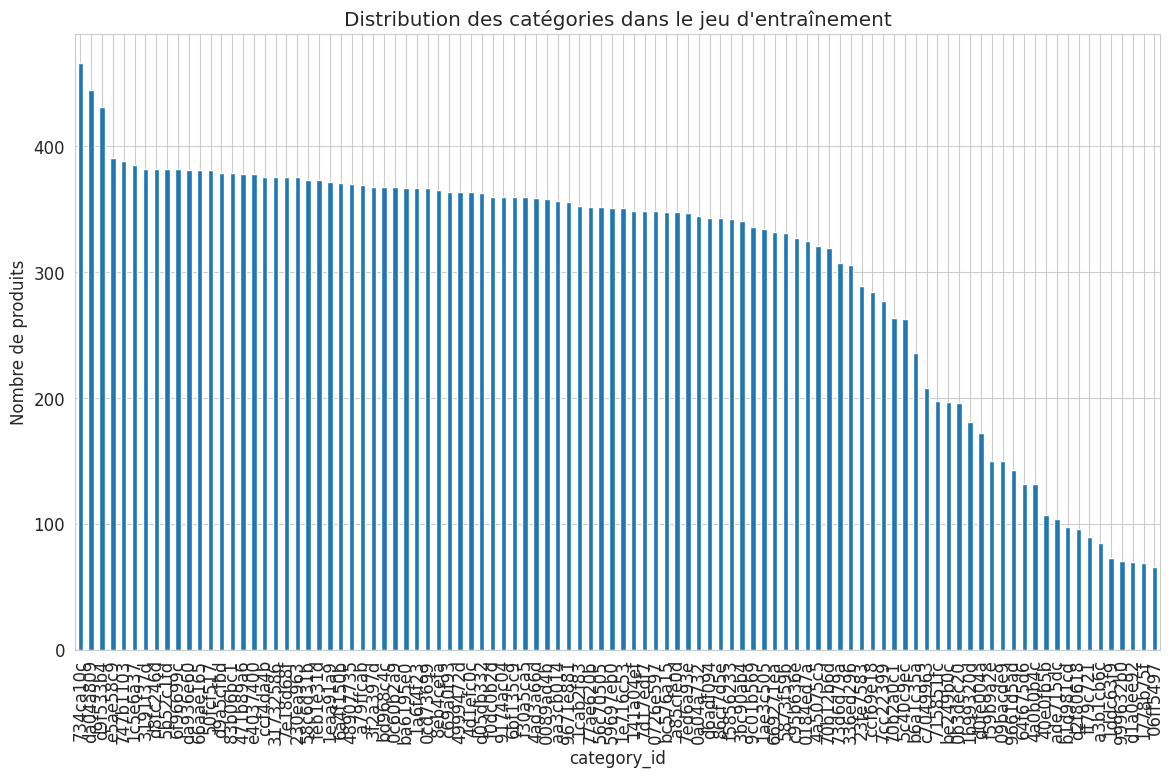

In [23]:
category_counts.plot(
    kind="bar",
    title="Distribution des catégories dans le jeu d'entraînement"
)
plt.ylabel("Nombre de produits")
plt.show()

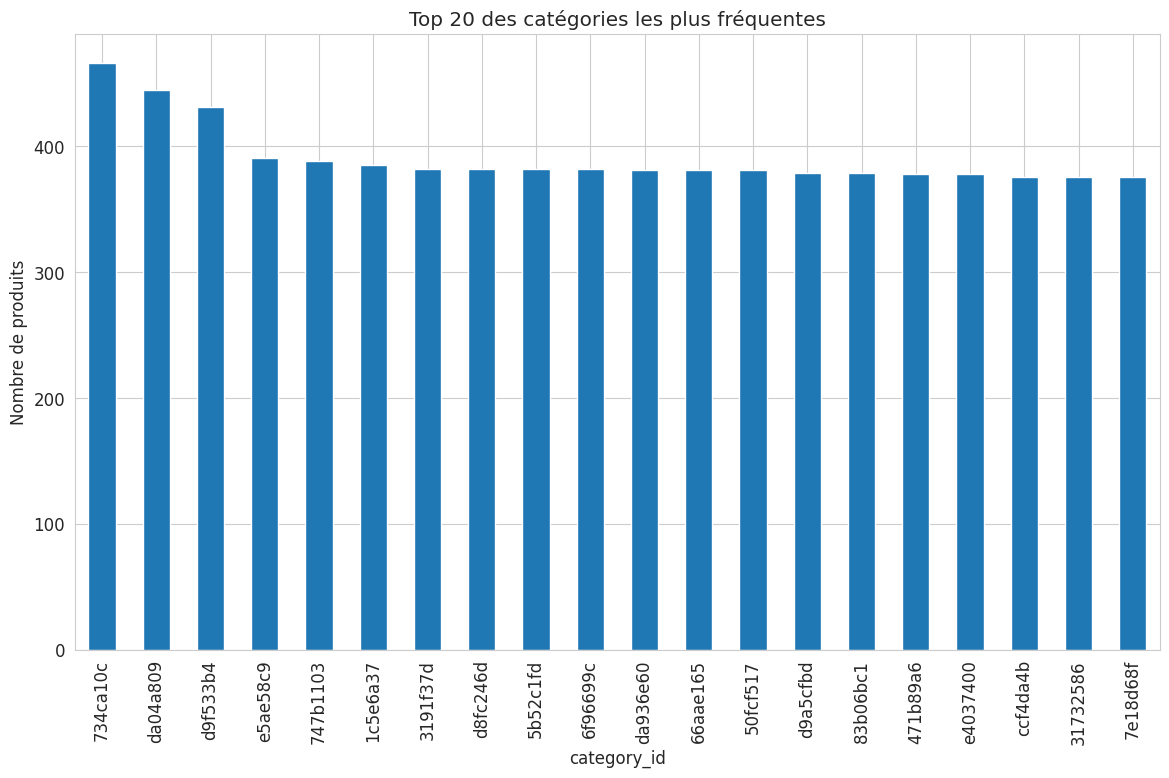

In [24]:
category_counts.head(20).plot(
    kind="bar",
    title="Top 20 des catégories les plus fréquentes"
)
plt.ylabel("Nombre de produits")
plt.show()

In [25]:
print(category_counts.head(20))

category_id
734ca10c    466
da04a809    445
d9f533b4    431
e5ae58c9    391
747b1103    388
1c5e6a37    385
3191f37d    382
d8fc246d    382
5b52c1fd    382
6f96699c    382
da936e60    381
66aae165    381
50fcf517    381
d9a5cfbd    379
83b06bc1    379
471b89a6    378
e4037400    378
ccf4da4b    376
31732586    376
7e18d68f    376
Name: count, dtype: int64


In [26]:
category_counts.tail(20)

category_id
be249b0c    197
0b3dec20    196
1b99320d    181
d0fe004a    172
f59b9a2e    150
09bacde9    150
9661d5ad    143
64f675d6    132
4a0b0b4c    132
40e0fb5b    107
ade715dc    104
b1d981cd     98
d2f80618     96
ff79c721     90
a3b1cb6c     85
1ddc63f9     73
999632b0     71
d1a0ee92     70
1778b75f     69
06ff5497     66
Name: count, dtype: int64

Le jeu d'entraînement comporte **100 catégories distinctes**, ce qui en fait un problème de classification multi-classes à grande échelle.  
La distribution des catégories est très déséquilibrée : quelques catégories concentrent la majorité des produits, tandis qu'un grand nombre sont très peu représentées.  
Cette configuration typique de **long tail** pose des défis importants : risque de sur-apprentissage (overfitting) sur les classes majoritaires, difficulté à bien prédire les classes rares, et nécessité d'adopter des stratégies adaptées pour gérer l'ensemble de la taxonomie.  



Bien que l’utilisation de `category_path` soit interdite lors de l’entraînement du modèle, cette colonne demeure précieuse pour l’analyse exploratoire : elle permet de mieux appréhender la structure de la taxonomie produit.

Grâce à `category_path`, il est possible d’explorer :
- la **profondeur moyenne** des catégories,
- la **variabilité** des chemins taxonomiques,
- la **cohérence** et la granularité de l’arborescence.

Cette analyse structurelle éclaire le choix entre une approche de classification **flat** (directe) ou **hierarchical** (niveau par niveau), et aide à anticiper les principaux défis liés à la complexité du catalogue.

In [27]:
for path in trainset["category_path"].head():
    print(f"Category Path: {path} => Depth: {len(str(path).split('/'))}")

Category Path: e3a03b90/72a77496/cfcafc53/b4ad0c8c/c0887815/c8ed6426/0a04a732 => Depth: 7
Category Path: e3a03b90/72a77496/cfcafc53/17b1bfd8/1ae3c505 => Depth: 5
Category Path: e3a03b90/107f27db/f59b9a2e/2050ad6d/1a6f4f23 => Depth: 5
Category Path: e3a03b90/e056c138/ec34940b/6ceb5201/1fd7323c/80bbe5dd/f5856233 => Depth: 7
Category Path: e3a03b90/79f03259/55eb19f3/ae8739c9/cbced5e2/7140b951/c7049963 => Depth: 7


La structure hiérarchique du catalogue apparaît de façon évidente à l'analyse des chemins de catégories (`category_path`). Une organisation en profondeur, avec plusieurs niveaux imbriqués.

In [28]:
trainset["path_depth"] = trainset["category_path"].apply(
    lambda x: len(str(x).split("/"))
)

trainset["path_depth"].describe()


count    30520.000000
mean         5.690072
std          1.031522
min          3.000000
25%          5.000000
50%          6.000000
75%          7.000000
max          8.000000
Name: path_depth, dtype: float64

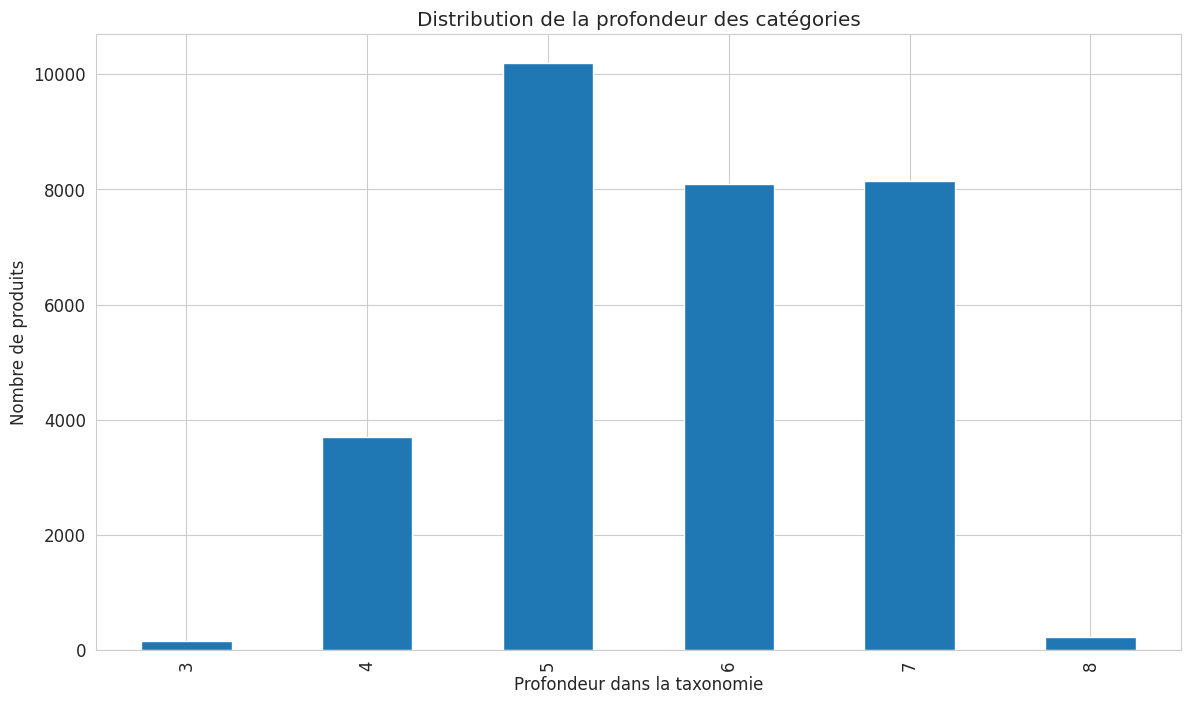

In [29]:
trainset["path_depth"].value_counts().sort_index().plot(
    kind="bar",
    title="Distribution de la profondeur des catégories"
)
plt.xlabel("Profondeur dans la taxonomie")
plt.ylabel("Nombre de produits")
plt.show()


In [30]:
trainset["path_depth"].value_counts().sort_index()

path_depth
3      150
4     3708
5    10187
6     8102
7     8152
8      221
Name: count, dtype: int64

En observant la distribution, je constate que la plupart des produits se situent entre les niveaux 5 et 7 de la taxonomie. Cela traduit une hiérarchie fine : les catégories feuilles sont très spécialisées, et la structure du catalogue est particulièrement profonde. 

Cette profondeur complexifie la tâche : les catégories sœurs sont souvent très proches sur le plan sémantique, ce qui fait que les erreurs de classification sont rarement flagrantes, mais plutôt subtiles.

Pour moi, cela implique qu’une approche hiérarchique aurait tout son sens pour exploiter la structure du catalogue. Cependant, démarrer par une classification flat, me semble être un choix pragmatique et efficace pour poser les premiers jalons du projet.

Les modèles de NLP sont particulièrement sensibles à plusieurs aspects des données textuelles:

- **La longueur des textes**: des textes trop courts peuvent manquer d'information, tandis que des textes très longs peuvent introduire du bruit ou nécessiter un traitement spécifique.
- **La variabilité des descriptions**: une forte hétérogénéité dans la façon dont les produits sont décrits peut compliquer la tâche du modèle.
- **La présence de textes atypiques**: certains produits peuvent n'avoir qu'un titre très bref ou, au contraire, une description exceptionnellement détaillée.

De mon point de vue, il serait donc interessant de chercher  à : 

- quantifier la **richesse informationnelle** réelle des champs textuels (`title`, `description`),
- identifier les **contraintes de preprocessing** à prévoir (troncature, padding, gestion des textes vides, etc.),
- anticiper les éventuels défis liés à la diversité et à la structure des textes produits.

In [31]:
trainset["title_length"] = trainset["title"].fillna("").apply(len)
trainset["description_length"] = trainset["description"].fillna("").apply(len)

In [32]:
trainset[["title_length", "description_length"]].describe()

,title_length,description_length
count,30520.000000,30520.000000
mean,98.182602,633.330799
std,57.304274,747.477019
min,1.000000,0.000000
25%,49.000000,0.000000
50%,87.000000,371.000000
75%,147.000000,1038.000000
max,725.000000,4000.000000


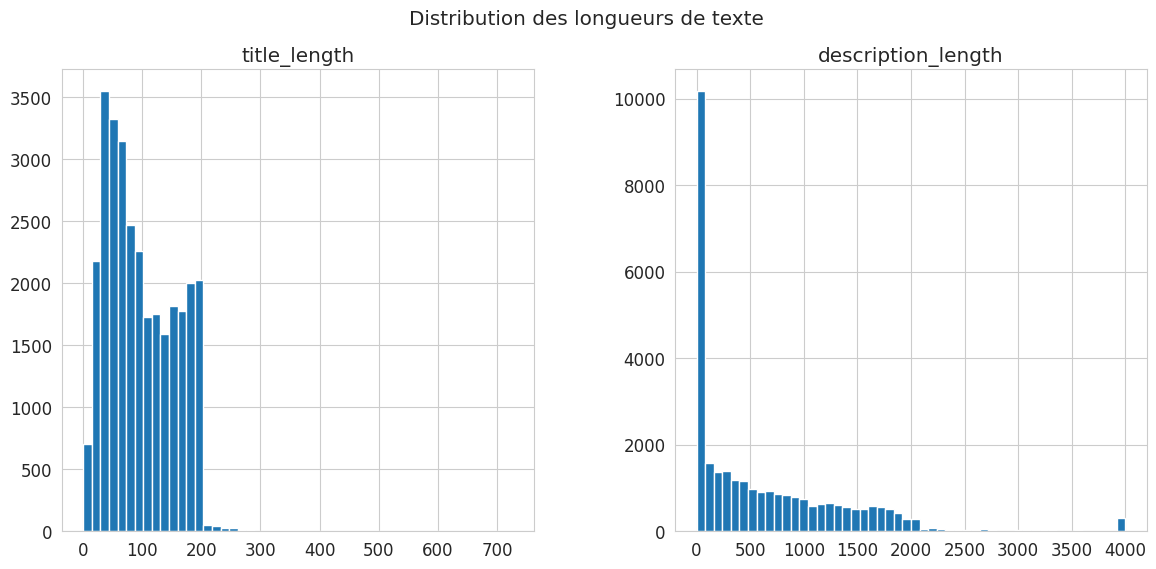

In [33]:
trainset[["title_length", "description_length"]].hist(
    bins=50,
    figsize=(14, 6)
)
plt.suptitle("Distribution des longueurs de texte")
plt.show()

Les titres des produits sont généralement courts, mais apportent une information essentielle et fiable: ils constituent le socle du modèle.  
À l'inverse, les descriptions présentent une forte variabilité: certaines sont absentes, d'autres très longues. Cette hétérogénéité peut introduire du bruit et compliquer le traitement automatique.

Pour exploiter au mieux ces deux champs textuels, il serait pertinent de:
- concaténer le `title` et la `description` afin d'enrichir la représentation du produit,
- tronquer les descriptions trop longues pour limiter le bruit et garantir une entrée homogène au modèle.

Cette stratégie permet de tirer parti de la complémentarité des informations tout en maîtrisant la qualité des données textuelles utilisées pour la classification.

Bien que `brand` et `color` soient des variables textuelles, elles se comportent en réalité comme des variables catégorielles classiques.

Pour évaluer leur utilité dans la modélisation, il est important d’analyser :

- **leur cardinalité** : combien de modalités distinctes existent pour chaque variable ?
- **leur potentiel discriminant** : certaines valeurs sont-elles fortement associées à des catégories spécifiques ?
- **leur niveau de bruit** : observe-t-on des valeurs aberrantes, des incohérences ou une forte hétérogénéité dans les libellés ?

Cette analyse permettra de déterminer comment exploiter au mieux ces variables dans le pipeline de classification.

In [34]:
trainset["brand"].nunique(), trainset["color"].nunique()

(8286, 2652)

In [35]:
trainset["brand"].value_counts()

brand
Microsoft    618
Sony         403
Samsung      272
Mindscape    262
Canon        245
            ... 
N\W            1
XINJIA         1
Kuvings        1
YPSMJLL        1
LQMILK         1
Name: count, Length: 8286, dtype: int64

In [36]:
brand_counts = trainset["brand"].value_counts(dropna=False)

brand_stats = brand_counts.describe()
brand_stats

count    8287.000000
mean        3.682877
std        16.485384
min         1.000000
25%         1.000000
50%         1.000000
75%         2.000000
max       858.000000
Name: count, dtype: float64

In [37]:
rare_brands_ratio = (brand_counts <= 2).mean()
print(f"Proportion de marques apparaissant au plus 2 fois: {rare_brands_ratio:.2%}")

Proportion de marques apparaissant au plus 2 fois: 77.33%


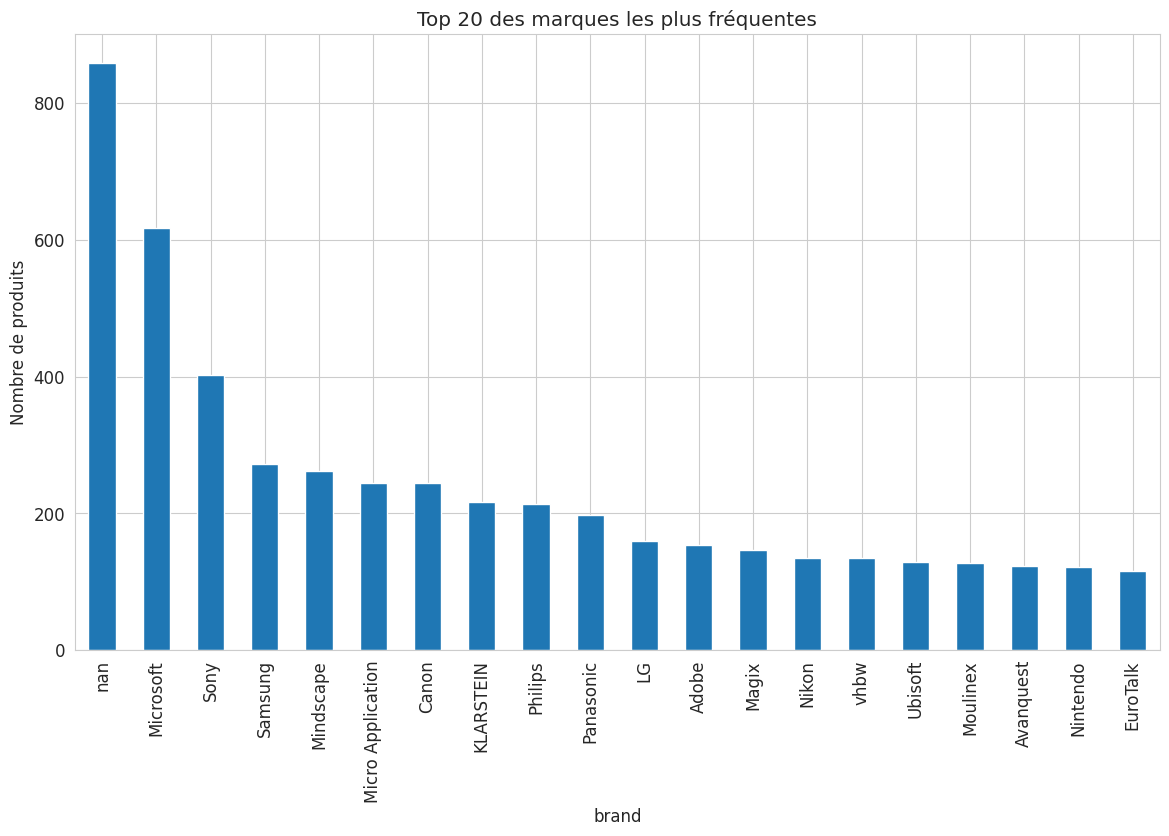

In [38]:
brand_counts.head(20).plot(
    kind="bar",
    title="Top 20 des marques les plus fréquentes"
)
plt.ylabel("Nombre de produits")
plt.show()

La variable `brand` se distingue par une **cardinalité exceptionnellement élevée** : on dénombre **8 287 marques différentes**, mais la distribution est extrêmement déséquilibrée.  
En effet, près de **50 % des marques n’apparaissent qu’une seule fois** et **75 % au plus deux fois**. À l’inverse, quelques marques très connues (Microsoft, Sony, Samsung…) sont surreprésentées, avec jusqu’à **618 occurrences pour Microsoft**. À noter que la modalité `NaN` (valeur manquante) est la plus fréquente, avec **858 occurrences**.

Ces marques dominantes sont généralement **très discriminantes** pour certaines catégories, mais la **grande majorité des marques sont rares**, ce qui pose plusieurs défis :

- **Faible capacité de généralisation** si chaque marque est traitée individuellement,
- **Risque de sur-apprentissage** sur les marques fréquentes,
- **Explosion de la dimensionnalité** lors de l’encodage.

Ainsi, même si `brand` est une variable potentiellement très informative, elle doit être **manipulée avec précaution**.  
La stratégie la plus pertinente pour moi, consiste à **regrouper les marques rares sous un token explicite** (`other_brand`) et à ne conserver que les marques fréquentes comme modalités individuelles.

In [39]:
trainset["color"].value_counts()

color
Noir                 3477
Blanc                1282
noir                  682
Rouge                 482
Argent                338
                     ... 
YG 300 jaune            1
V9A                     1
10 Mixcolors            1
Fleur 6                 1
Noir et Aluminium       1
Name: count, Length: 2652, dtype: int64

In [40]:
color_counts = trainset["color"].value_counts(dropna=False)
color_stats = color_counts.describe()
color_stats

count     2653.000000
mean        11.503958
std        315.779291
min          1.000000
25%          1.000000
50%          1.000000
75%          1.000000
max      15800.000000
Name: count, dtype: float64

In [41]:
# Proportion de couleurs rares
rare_colors_ratio = (color_counts <= 2).mean()
print(f"Proportion de couleurs apparaissant au plus 2 fois: {rare_colors_ratio:.2%}")

Proportion de couleurs apparaissant au plus 2 fois: 88.16%


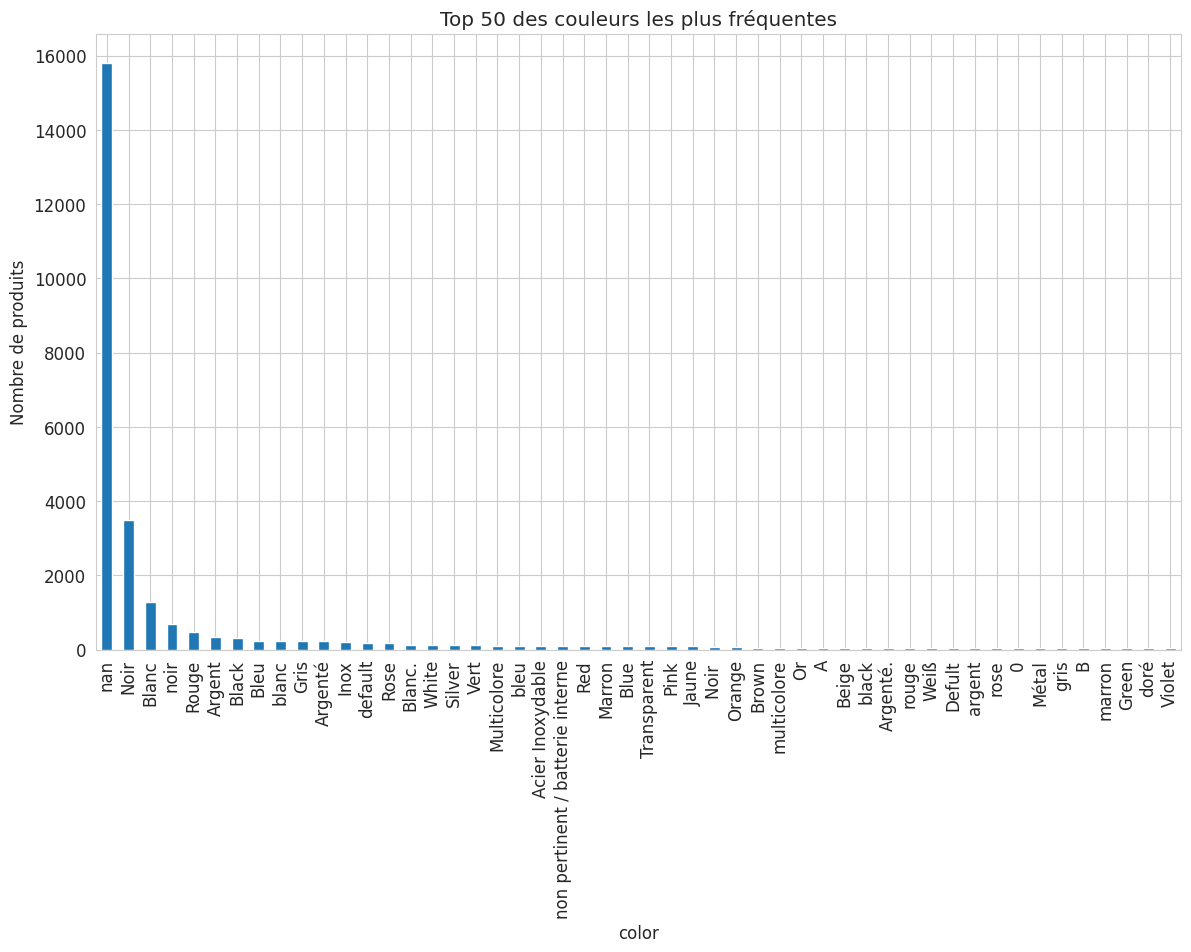

In [42]:
color_counts.head(50).plot(
    kind="bar",
    title="Top 50 des couleurs les plus fréquentes"
)
plt.ylabel("Nombre de produits")
plt.show()

La variable `color` présente une **forte variabilité lexicale** : on observe des différences de langue (`Noir`, `Black`), de casse (`Noir`, `noir`), ainsi que de nombreuses incohérences (valeurs manquantes, mentions non pertinentes comme "batterie interne", ou encore des codes internes tels que "A", "O", "B" qui ne correspondent pas à des couleurs réelles).  
Cette hétérogénéité se traduit par la présence de valeurs très spécifiques, de combinaisons libres et de codifications marketing ou internes, rendant la variable difficile à exploiter comme une variable catégorielle classique.

Malgré son **potentiel informatif intuitif**, la variable `color` ne peut être utilisée que comme un **signal faible complémentaire**.  
Pour la modélisation, il sera pertinent de :
- regrouper les couleurs dominantes sous des modalités individuelles,
- attribuer la valeur `"other_color"` à toutes les couleurs rares ou non informatives.

Cette stratégie permettra d'exploiter au mieux l'information disponible tout en limitant le bruit et la complexité induits par la variabilité lexicale.

Preprocessing

Une petit précision qu'on sait tous, que je souhaite cependant rappélé

> **Note :** Il est important de rappeler que les modèles de machine learning ne traitent que des valeurs numériques. Toutes les variables catégorielles ou textuelles doivent donc être converties en représentations numériques appropriées avant d’être utilisées pour l’entraînement ou la prédiction.

> **Rappel fondamental :**  
> Les modèles de machine learning ne manipulent que des valeurs numériques.  
> Il est donc indispensable de convertir toutes les variables catégorielles ou textuelles en représentations numériques adaptées (encodage, vectorisation, embeddings, etc.) avant de les utiliser pour l’entraînement ou la prédiction.

Gestion explicite des valeurs manquantes: On distingue ici les valeurs manquantes informatives (absence réelle) des valeurs manquantes accidentelles.

In [43]:
# === 1. Gestion des valeurs manquantes ===
# Les champs texte manquants sont remplacés par un token explicite
# afin de conserver l'information d'absence pour le modèle.

for col in ["description", "brand"]:
    trainset[col] = trainset[col].fillna("unknown")
    testset[col] = testset[col].fillna("unknown")

# La couleur est très souvent absente et peu discriminante dans certaines catégories
trainset["color"] = trainset["color"].fillna("no_color")
testset["color"] = testset["color"].fillna("no_color")


Normalisation & réduction de cardinalité – couleur

Les couleurs rares sont regroupées afin de limiter la sparsité et le bruit, tout en conservant l’information pour les couleurs dominantes

In [44]:
# === 2. Nettoyage et regroupement des couleurs ===

color_counts = trainset["color"].str.lower().value_counts()
frequent_colors = set(color_counts[color_counts > 50].index)

def clean_color(c):
    c = str(c).strip().lower()
    if c in frequent_colors and c != "no_color":
        return c
    return "other_color"

trainset["color_clean"] = trainset["color"].apply(clean_color)
testset["color_clean"] = testset["color"].apply(clean_color)


Regroupement des marques rares (très important)

La majorité des marques n’apparaissent qu’une seule fois. Les regrouper permet de stabiliser l’apprentissage et d’éviter un sur-apprentissage sur des signaux trop faibles

In [45]:
# === 3. Nettoyage et regroupement des marques ===

brand_counts = trainset["brand"].value_counts()
frequent_brands = set(brand_counts[brand_counts > 10].index)

def clean_brand(b):
    b = str(b).strip()
    if b in frequent_brands and b != "unknown":
        return b
    return "other_brand"

trainset["brand_clean"] = trainset["brand"].apply(clean_brand)
testset["brand_clean"] = testset["brand"].apply(clean_brand)


Fusion des champs textuels

In [46]:
# === 4. Fusion titre + description ===
# Le titre porte généralement l'information principale,
# la description apporte un contexte complémentaire (quand disponible).

trainset["text"] = (
    trainset["title"].fillna("") + " " + trainset["description"].fillna("")
).str.strip()

testset["text"] = (
    testset["title"].fillna("") + " " + testset["description"].fillna("")
).str.strip()

Troncature (avant embedding)

In [47]:
# === 5. Troncature des textes ===
MAX_TEXT_LENGTH = 512

trainset["text"] = trainset["text"].str.slice(0, MAX_TEXT_LENGTH)
testset["text"] = testset["text"].str.slice(0, MAX_TEXT_LENGTH)

Encodage du target

In [48]:
# === 6. Encodage de la variable cible ===
label_encoder = LabelEncoder()
trainset["category_label"] = label_encoder.fit_transform(trainset["category_id"])

Encodage des variables catégorielles

In [49]:
# === 7. Encodage des variables catégorielles ===

cat_encoder = OrdinalEncoder(
    handle_unknown="use_encoded_value",
    unknown_value=-1
)

trainset[["brand_enc", "color_enc"]] = cat_encoder.fit_transform(
    trainset[["brand_clean", "color_clean"]]
)

testset[["brand_enc", "color_enc"]] = cat_encoder.transform(
    testset[["brand_clean", "color_clean"]]
)


In [50]:
# -------------------------------
# Features non structurées (texte)
# -------------------------------
X_text_train = trainset["text"].values
X_text_test  = testset["text"].values

# -------------------------------
# Features structurées (brand, color)
# -------------------------------
X_struct_train = trainset[["brand_enc", "color_enc"]].values.astype(np.int64)
X_struct_test  = testset[["brand_enc", "color_enc"]].values.astype(np.int64)

# -------------------------------
# Cible
# -------------------------------
y_train = trainset["category_label"].values


In [51]:
X_text_train[:2]

array(["Lindy 37771 Cable d'antenne Premium M/M 1m Prises: standard coaxial, or, pour un meilleur tranfert du signal et une meilleure longévité.",
       'Camescope Camera Video 4K 30MP Caméscope avec Microphone Caméra Vidéo à Ecran Tactile de 3,0" Vlogging Caméra 16X Zoom Numérique avec Télécommande unknown'],
      dtype=object)

In [52]:
X_struct_train[:2]

array([[407,  11],
       [407,  20]])

## Modelisation

Je me suis posé la question suivante : Comment classifier efficacement des produits e-commerce à partir de leurs attributs texte (titre, description) et structurés (marque, couleur) ?
Mon constat initial : Les données textuelles sont riches mais bruyantes, tandis que les features structurées (marque, couleur) apportent un signal catégoriel fort mais incomplet. Combiner donc les deux est une approche peut être interessant. Pour le pipeline, je vais suivre l'architecture presentant precedemment qui convaindra non seulement pour la classification flat mais aussi hiérarchique.

Pour aborder la modélisation, il est judicieux de débuter par une approche de référence simple. J’opte donc pour une combinaison de TF-IDF (Term Frequency–Inverse Document Frequency) appliqué aux textes bruts, suivie d’un modèle de régression logistique pour la classification, qui est là une classification flat (non hiérarchique).

Le TF-IDF transforme les textes en vecteurs numériques exploitables par le modèle : la fréquence d’apparition de chaque mot dans un document (TF) est pondérée par la rareté de ce mot dans l’ensemble du corpus (IDF). Cette méthode met en avant les termes caractéristiques tout en atténuant l’influence des mots trop courants. Il est essentiel de supprimer les stop words pour éviter qu’ils ne biaisent la représentation.

Il convient toutefois de rappeler que le TF-IDF ne capture pas la structure ou le sens des phrases : il se limite à compter les occurrences de tokens, sans compréhension sémantique.

In [53]:
# je veux juste avoir une idée du nombre de features générées par le TF-IDF
tfidf = TfidfVectorizer()
tfidf.fit(X_text_train)
print(f"Nombre de features TF-IDF générées: {len(tfidf.get_feature_names_out())}")

Nombre de features TF-IDF générées: 75536


In [54]:
def clean_stopwords(stopwords):
    return [
        re.sub(r"[^\w]", "", w.lower())
        for w in stopwords
        if len(re.sub(r"[^\w]", "", w)) > 1
    ]

final_stopwords_list = clean_stopwords(fr_stop | en_stop)

# Custom transformer to extract structured features
class StructFeatureExtractor(BaseEstimator, TransformerMixin):
    def fit(self, X, y=None):
        return self
    def transform(self, X):
        # X is a DataFrame or ndarray with brand_enc and color_enc
        return X

# Vectorisation texte
tfidf = TfidfVectorizer(max_features=20000,  # après différentes expérimentations, 20000 semble un bon compromis
                        min_df=5, 
                        stop_words=final_stopwords_list)
X_text_train_tfidf = tfidf.fit_transform(X_text_train)
X_text_test_tfidf = tfidf.transform(X_text_test)

# Standardisation des features structurées (optionnel mais conseillé)
scaler = StandardScaler()
X_struct_train_scaled = scaler.fit_transform(X_struct_train)
X_struct_test_scaled = scaler.transform(X_struct_test)

# Concaténation des features texte et structurées
X_train_combined = sparse.hstack([X_text_train_tfidf, X_struct_train_scaled])
X_test_combined = sparse.hstack([X_text_test_tfidf, X_struct_test_scaled])

# Modèle de classification
clf = LogisticRegression(max_iter=200, class_weight="balanced", verbose=1)
clf.fit(X_train_combined, y_train)

y_pred_combined = clf.predict(X_test_combined)
testset["combined_pred_category_id"] = label_encoder.inverse_transform(y_pred_combined)

testset[["product_id", "combined_pred_category_id"]].head()

[Parallel(n_jobs=1)]: Done   1 out of   1 | elapsed:   28.2s finished


,product_id,combined_pred_category_id
0,20cbaaa9-f662-4309-a614-9c074cf6bd1a,f30a5ca5
1,e81b3d42-261f-4a19-9e48-d7a6b9142f79,e4037400
2,a972f069-a2ef-4e89-bcbb-7628cf33a6e4,747b1103
3,4b3b7ab3-4381-41d5-86b7-c7c6d7f0b567,a79ffcab
4,de1695f6-3f51-4ab7-a9ca-967915ac8738,7cc22399


In [55]:
# Prédiction sur le train
y_pred_train_combined = clf.predict(X_train_combined)
trainset["combined_pred_category_id"] = label_encoder.inverse_transform(y_pred_train_combined)

# F1-score train
f1_macro_train = f1_score(y_train, y_pred_train_combined, average="macro")
f1_micro_train = f1_score(y_train, y_pred_train_combined, average="micro")
print(f"Train F1-score macro : {f1_macro_train:.4f}")
print(f"Train F1-score micro : {f1_micro_train:.4f}")

# Prédiction sur le test 
y_true_test = testset["category_id"]
y_pred_test = testset["combined_pred_category_id"]

f1_macro_test = f1_score(y_true_test, y_pred_test, average="macro")
f1_micro_test = f1_score(y_true_test, y_pred_test, average="micro")
print(f"Test F1-score macro : {f1_macro_test:.4f}")
print(f"Test F1-score micro : {f1_micro_test:.4f}")


Train F1-score macro : 0.8907
Train F1-score micro : 0.9030
Test F1-score macro : 0.8002
Test F1-score micro : 0.8346


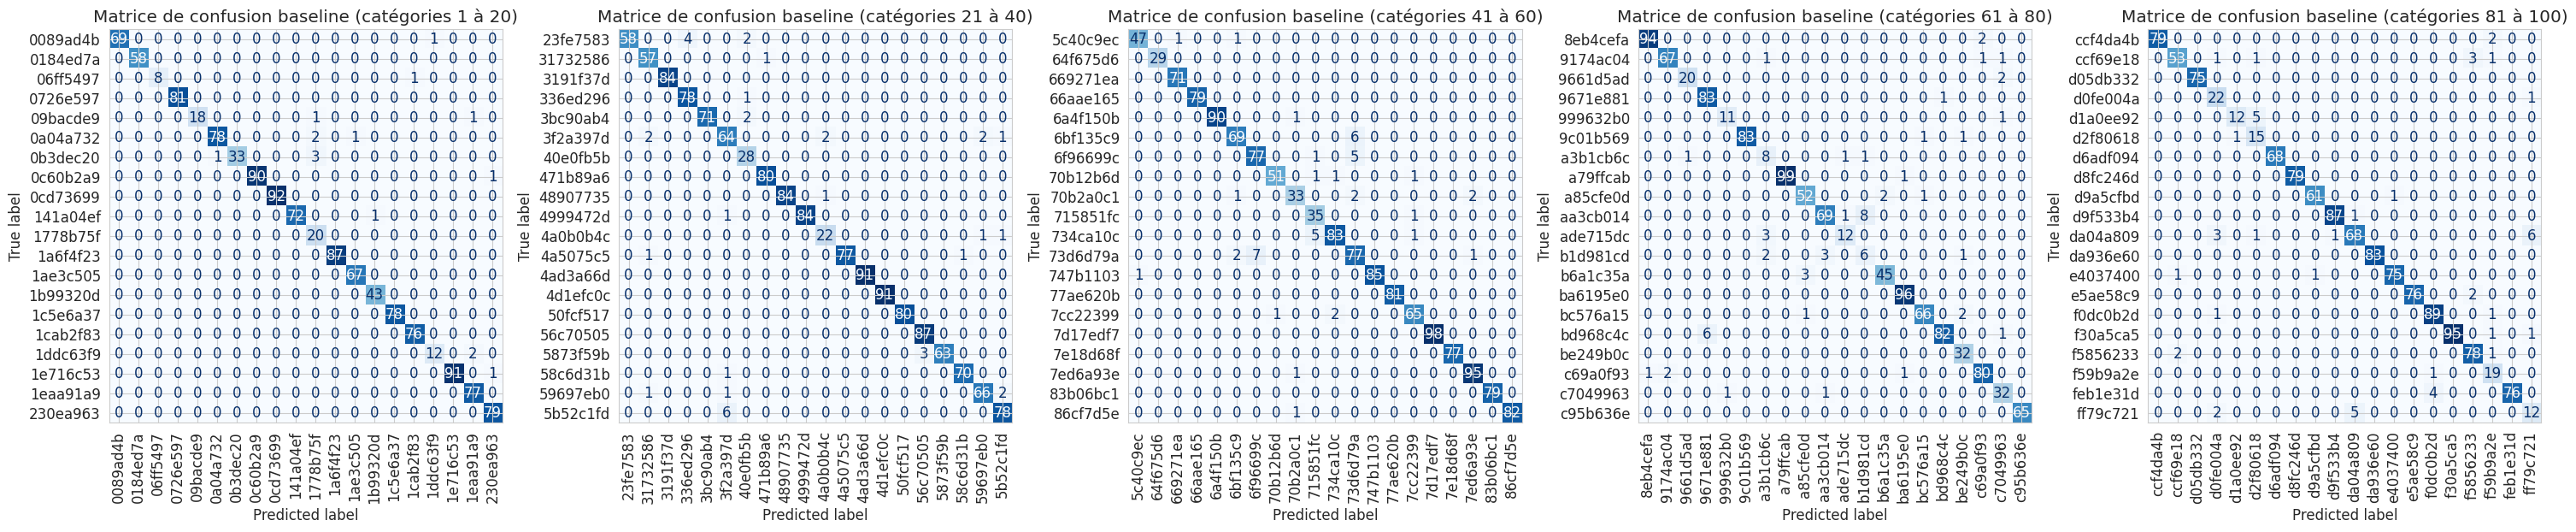

In [56]:
n_classes = len(label_encoder.classes_)
group_size = 20
n_groups = math.ceil(n_classes / group_size)

fig, axes = plt.subplots(1, n_groups, figsize=(6 * n_groups, 16))

if n_groups == 1:
    axes = [axes]

for i in range(n_groups):
    start = i * group_size
    end = min((i + 1) * group_size, n_classes)
    labels_group = list(label_encoder.classes_)[start:end]
    cm_group = confusion_matrix(y_true_test, y_pred_test, labels=labels_group)
    disp = ConfusionMatrixDisplay(confusion_matrix=cm_group, display_labels=labels_group)
    disp.plot(ax=axes[i], xticks_rotation=90, cmap="Blues", colorbar=False)
    axes[i].set_title(f"Matrice de confusion baseline (catégories {start+1} à {end})")

plt.tight_layout()
plt.show()

**Note d'affichage :**  
Pour une meilleure lisibilité des visualisations (matrices de confusion, graphiques larges, etc.), je recommande d'utiliser un écran large ou adapter le code d'affichage verticalement.  
Personnellement, je travaille avec un écran 34 pouces.

Lorsque j’analyse les résultats du modèle baseline (TF-IDF + régression logistique), plusieurs constats importants émergent.

Sur le jeu d’entraînement, les scores sont très élevés :  
- **F1-score macro : 0.8907**
- **F1-score micro : 0.9030**

Cela indique que le modèle capture efficacement la structure des données et parvient à prédire correctement la majorité des catégories, y compris les classes rares (macro) et fréquentes (micro).  
Cependant, ces performances sur le train doivent être interprétées avec prudence : elles peuvent traduire un certain sur-apprentissage, notamment dans un contexte de fort déséquilibre des classes.

Sur le jeu de test, les scores diminuent logiquement, mais restent solides :  
- **F1-score macro : 0.8002**
- **F1-score micro : 0.8346**

On observe donc une légère perte de généralisation, mais le modèle demeure robuste. Le F1 macro, inférieur au micro, confirme que les classes minoritaires sont plus difficiles à prédire : le modèle tend à privilégier les catégories majoritaires, ce qui est classique dans ce type de problème.

L’analyse de la matrice de confusion montre que la plupart des classes sont bien prédites, même si certaines erreurs subsistent, notamment entre catégories proches ou sœurs dans la taxonomie. L’utilisation de codes pour les labels limite toutefois l’interprétation métier : des noms plus explicites (ex : vêtements, sport, etc.) faciliteraient l’analyse des confusions.

Ce premier modèle atteint 80% de F1 macro avec une architecture relativement simple, ce qui est très prometteur.

Suite au modèle de régression logistique qui a montré de bonnes performances (F1 macro de 80 %), j'ai décidé d'explorer une approche plus avancée avec le Deep Learning. Cette décision repose sur plusieurs raisons :

- **Capture de sémantique complexe** : Les descriptions produits contiennent des nuances que les méthodes bag-of-words ne peuvent saisir.
- **Relations contextuelles** : L'ordre des mots et leur contexte sont cruciaux pour comprendre les spécificités produits.
- **Scalabilité future** : Avec plus de données, les modèles de deep learning offrent un meilleur potentiel d'amélioration.

Pour cette modélisation, j'ai opté pour un extracteur de features basé sur un modèle multi-langue(en effet, j'ai observé des donnée ici en français mais aussi certains en anglais) : RoBERTa comme backbone (all-MiniLM-L6-v2, une version légère). J'ai appliqué un fine-tuning partiel, en dégelant uniquement les 2 dernières couches pour un transfert learning efficace. De plus, j'ai ajouté un CNN multi-n-grammes pour capturer des motifs locaux à différentes échelles (1 à 5 mots), au cas où le backbone manquerait certaines informations.

Les données structurées (marque et couleur) sont transformées via des embeddings apprenables, puis combinées avant d'être passées dans une structure classique de classification en deep learning (softmax comme output layer).

## Configuration matérielle pour le Deep Learning

Pour les sections consacrées au deep learning, j'utilise mon GPU Nvidia GeForce RTX 5060, qui offre des performances modeste pour entraîner les modèles sur ce jeu de données.

In [57]:
def seed_everything(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

    # Pour une reproductibilité stricte (un peu plus lent)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

def seed_worker(worker_id):
    worker_seed = SEED + worker_id
    np.random.seed(worker_seed)
    random.seed(worker_seed)



SEED = 42
seed_everything(SEED)


Pour le modèle d'embedding, je vais utiliser un modèle multi-language. En effet, etant donnée que les données peuvent être dans differentes langues (comme constater ici, j'ai observer des textes en français mais aussi en anglais). L'approche est important pour eux d'après leur guideline, je vais donc utiliser un modèle leger pour un entrainement un peu rapide et peut-être par chance qui serait tout aussi performant que le modèle lourd.

In [58]:
# 1. Tokenizer & RoBERTa model
MODEL_NAME = "sentence-transformers/all-MiniLM-L6-v2"
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)
roberta = AutoModel.from_pretrained(MODEL_NAME)

roberta = AutoModel.from_pretrained(MODEL_NAME)

# Dégelez les dernières couches
for param in roberta.parameters():
    param.requires_grad = False  # Geler tout d'abord

# Dégelez les 2 dernières couches
for layer in roberta.encoder.layer[-2:]:
    for param in layer.parameters():
        param.requires_grad = True

# 2. Dataset
class ProductDataset(Dataset):
    def __init__(
        self,
        texts,
        struct_feats=None,
        labels=None,
        max_length=MAX_TEXT_LENGTH
    ):
        self.texts = texts
        self.struct_feats = struct_feats
        self.labels = labels
        self.max_length = max_length

        # Flag utile pour le modèle
        self.has_struct = struct_feats is not None

    def __len__(self):
        return len(self.texts)

    def __getitem__(self, idx):
        encoding = tokenizer(
            self.texts[idx],
            truncation=True,
            padding="max_length",
            max_length=self.max_length,
            return_tensors="pt"
        )

        item = {
            "input_ids": encoding["input_ids"].squeeze(0),
            "attention_mask": encoding["attention_mask"].squeeze(0),
        }

        if self.has_struct:
            item["struct"] = torch.tensor(
                self.struct_feats[idx], dtype=torch.long
            )

        if self.labels is not None:
            item["label"] = torch.tensor(
                self.labels[idx], dtype=torch.long
            )

        return item


# 3. CNN block for n-gram extraction
class NgramCNN(nn.Module):
    def __init__(self, embed_dim, ngram_sizes=(1,2,3,4,5), num_filters=64):
        super().__init__()
        self.convs = nn.ModuleList([
            nn.Conv1d(embed_dim, num_filters, kernel_size=n) for n in ngram_sizes
        ])

    def forward(self, x):
        # x: (batch, seq_len, embed_dim)
        x = x.transpose(1, 2)  # (batch, embed_dim, seq_len)
        features = [F.relu(conv(x)).max(dim=2)[0] for conv in self.convs]
        return torch.cat(features, dim=1)  # (batch, num_filters * len(ngram_sizes))

# 4. Main Model

class ProductClassifier(nn.Module):
    def __init__(
        self,
        roberta,
        struct_vocab_sizes=None,
        struct_emb_dim=32,
        ngram_filters=64,
        ngram_sizes=(1,2),
        num_classes=100,
        dropout=0.3
    ):
        super().__init__()

        self.roberta = roberta
        self.text_embed_dim = roberta.config.hidden_size
        self.cnn = NgramCNN(self.text_embed_dim, ngram_sizes, ngram_filters)

        self.use_struct = struct_vocab_sizes is not None

        if self.use_struct:
            self.struct_embs = nn.ModuleList([
                nn.Embedding(vocab_size, struct_emb_dim)
                for vocab_size in struct_vocab_sizes
            ])
            self.struct_proj = nn.Linear(
                len(struct_vocab_sizes) * struct_emb_dim, 128
            )
            fusion_dim = len(ngram_sizes) * ngram_filters + 128
        else:
            fusion_dim = len(ngram_sizes) * ngram_filters

        self.dropout = nn.Dropout(dropout)
        self.bn1 = nn.BatchNorm1d(fusion_dim)
        self.fc1 = nn.Linear(fusion_dim, 256)
        self.bn2 = nn.BatchNorm1d(256)
        self.fc2 = nn.Linear(256, 128)
        self.bn3 = nn.BatchNorm1d(128)
        self.out = nn.Linear(128, num_classes)

    def forward(self, input_ids, attention_mask, struct=None):

        outputs = self.roberta(
            input_ids=input_ids,
            attention_mask=attention_mask
        )
        last_hidden = outputs.last_hidden_state
        text_feat = self.cnn(last_hidden)

        if self.use_struct and struct is not None:
            struct_emb = [
                emb(struct[:, i]) for i, emb in enumerate(self.struct_embs)
            ]
            struct_emb = torch.cat(struct_emb, dim=1)
            struct_feat = self.struct_proj(struct_emb)
            x = torch.cat([text_feat, struct_feat], dim=1)
        else:
            x = text_feat

        x = self.dropout(F.relu(self.bn1(x)))
        x = self.dropout(F.relu(self.bn2(self.fc1(x))))
        x = self.dropout(F.relu(self.bn3(self.fc2(x))))

        return self.out(x)


2026-01-19 06:30:08.069370: I tensorflow/core/util/port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
2026-01-19 06:30:08.855251: I tensorflow/core/platform/cpu_feature_guard.cc:210] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F AVX512_VNNI AVX512_BF16 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
2026-01-19 06:30:11.967827: I tensorflow/core/util/port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


In [59]:

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
BATCH_SIZE = 32
EPOCHS = 100
num_classes = len(label_encoder.classes_)

# Taille des vocabulaires pour les embeddings structurés
brand_vocab_size = int(trainset["brand_enc"].max()) + 2  # +1 pour unknown, +1 pour sécurité
color_vocab_size = int(trainset["color_enc"].max()) + 2
struct_vocab_sizes = [brand_vocab_size, color_vocab_size]

# First, create a validation set from trainset (e.g., 20% for validation)
val_size = int(0.2 * len(trainset))
train_size = len(trainset) - val_size

train_subset, val_subset = random_split(
    list(zip(X_text_train, X_struct_train, y_train)),
    [train_size, val_size],
)

train_dataset = ProductDataset(
    texts=[X_text_train[i] for i in train_subset.indices],
    struct_feats=[X_struct_train[i] for i in train_subset.indices],
    labels=[y_train[i] for i in train_subset.indices],
    max_length=MAX_TEXT_LENGTH
)

val_dataset = ProductDataset(
    texts=[X_text_train[i] for i in val_subset.indices],
    struct_feats=[X_struct_train[i] for i in val_subset.indices],
    labels=[y_train[i] for i in val_subset.indices],
    max_length=MAX_TEXT_LENGTH
)

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=8,
    worker_init_fn=seed_worker,
    generator=torch.Generator().manual_seed(SEED),
    pin_memory=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=8,
    worker_init_fn=seed_worker,
    generator=torch.Generator().manual_seed(SEED),
    pin_memory=True
)

model = ProductClassifier(
    roberta=roberta,
    struct_vocab_sizes=struct_vocab_sizes,
    num_classes=num_classes
).to(DEVICE)

optimizer = torch.optim.AdamW(model.parameters(), lr=1e-4)

class FocalLoss(nn.Module):
    def __init__(self, alpha=1, gamma=2):
        super().__init__()
        self.alpha = alpha
        self.gamma = gamma
    
    def forward(self, inputs, targets):
        BCE_loss = F.cross_entropy(inputs, targets, reduction='none')
        pt = torch.exp(-BCE_loss)
        F_loss = self.alpha * (1-pt)**self.gamma * BCE_loss
        return F_loss.mean()
    
# Calcule les poids de classe basés sur la fréquence inverse
class_counts = np.bincount(y_train)
total = len(y_train)
# alpha_t = (total - class_counts) / total  # Approche 1
# Ou bien :
alpha_t = total / (len(class_counts) * class_counts)  # Approche 2
alpha_t = alpha_t / alpha_t.sum()  # Normaliser

# Utiliser la moyenne des alpha comme valeur
alpha_value = float(alpha_t.mean())
criterion = FocalLoss(alpha=alpha_value, gamma=1.5)

criterion = FocalLoss(alpha=1, gamma=2)

# Learning rate scheduler for decay
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer, mode='max', factor=0.5, patience=3
)

# Early stopping parameters
patience = 5
best_f1 = 0.0
epochs_no_improve = 0
best_model_path = "best_model.pth"

for epoch in range(EPOCHS):
    # Training phase
    model.train()
    total_loss = 0
    loop = tqdm(train_loader, desc=f"Epoch {epoch+1}/{EPOCHS}", leave=False)
    for batch in loop:
        input_ids = batch['input_ids'].to(DEVICE)
        attention_mask = batch['attention_mask'].to(DEVICE)
        struct = batch.get('struct')
        if struct is not None:
            struct = struct.to(DEVICE)
        labels = batch['label'].to(DEVICE)

        optimizer.zero_grad()
        outputs = model(input_ids, attention_mask, struct)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()
        total_loss += loss.item()

        loop.set_postfix(loss=loss.item())

    avg_train_loss = total_loss / len(train_loader)

    # Validation phase
    model.eval()
    val_preds = []
    val_labels = []
    val_loss = 0
    with torch.no_grad():
        for batch in val_loader:
            input_ids = batch['input_ids'].to(DEVICE)
            attention_mask = batch['attention_mask'].to(DEVICE)
            struct = batch.get('struct')
            if struct is not None:
                struct = struct.to(DEVICE)
            labels = batch['label'].to(DEVICE)

            outputs = model(input_ids, attention_mask, struct)
            loss = criterion(outputs, labels)
            val_loss += loss.item()

            preds = torch.argmax(outputs, dim=1).cpu().numpy()
            val_preds.extend(preds)
            val_labels.extend(labels.cpu().numpy())

    avg_val_loss = val_loss / len(val_loader)
    val_accuracy = accuracy_score(val_labels, val_preds)
    val_f1_macro = f1_score(val_labels, val_preds, average='macro')
    val_f1_micro = f1_score(val_labels, val_preds, average='micro')

    print(f"Epoch {epoch+1}/{EPOCHS} - Train Loss: {avg_train_loss:.4f} - Val Loss: {avg_val_loss:.4f} - Val Acc: {val_accuracy:.4f} - Val F1 Macro: {val_f1_macro:.4f} - Val F1 Micro: {val_f1_micro:.4f}")

    # Scheduler step based on val F1 macro
    scheduler.step(val_f1_macro)

    # Check for best model
    if val_f1_macro > best_f1:
        best_f1 = val_f1_macro
        epochs_no_improve = 0
        torch.save(model.state_dict(), best_model_path)
        print(f"Best model saved with F1 Macro: {best_f1:.4f}")
    else:
        epochs_no_improve += 1

    # Early stopping
    if epochs_no_improve >= patience:
        print(f"Early stopping at epoch {epoch+1}")
        break

# Load the best model
model.load_state_dict(torch.load(best_model_path))

Epoch 1/100:   0%|          | 0/763 [00:00<?, ?it/s]

Epoch 1/100 - Train Loss: 3.9233 - Val Loss: 3.0313 - Val Acc: 0.4949 - Val F1 Macro: 0.3542 - Val F1 Micro: 0.4949
Best model saved with F1 Macro: 0.3542


Epoch 2/100:   0%|          | 0/763 [00:00<?, ?it/s]

Epoch 2/100 - Train Loss: 2.6098 - Val Loss: 1.8043 - Val Acc: 0.6291 - Val F1 Macro: 0.4806 - Val F1 Micro: 0.6291
Best model saved with F1 Macro: 0.4806


Epoch 3/100:   0%|          | 0/763 [00:00<?, ?it/s]

Epoch 3/100 - Train Loss: 1.7807 - Val Loss: 1.2831 - Val Acc: 0.7018 - Val F1 Macro: 0.5693 - Val F1 Micro: 0.7018
Best model saved with F1 Macro: 0.5693


... (63 outputs left out)

Epoch 35/100 - Train Loss: 0.0671 - Val Loss: 0.5364 - Val Acc: 0.8404 - Val F1 Macro: 0.8011 - Val F1 Micro: 0.8404


Epoch 36/100:   0%|          | 0/763 [00:00<?, ?it/s]

Epoch 36/100 - Train Loss: 0.0619 - Val Loss: 0.5303 - Val Acc: 0.8453 - Val F1 Macro: 0.8075 - Val F1 Micro: 0.8453
Early stopping at epoch 36


<All keys matched successfully>

In [60]:
# Predict on train set for deep learning model
train_dataset_pred = ProductDataset(
    texts=X_text_train,
    struct_feats=X_struct_train,
    labels=None,  # No labels for prediction
    max_length=MAX_TEXT_LENGTH
)
train_loader_pred = DataLoader(
    train_dataset_pred,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=8,
    pin_memory=True
)

model.eval()
all_preds_train = []
with torch.no_grad():
    for batch in tqdm(train_loader_pred, desc="Predicting on train set"):
        input_ids = batch['input_ids'].to(DEVICE)
        attention_mask = batch['attention_mask'].to(DEVICE)
        struct = batch['struct'].to(DEVICE)

        outputs = model(input_ids, attention_mask, struct)
        preds = torch.argmax(outputs, dim=1).cpu().numpy()
        all_preds_train.extend(preds)

# Convert predictions back to category IDs
trainset["deep_pred_category_id"] = label_encoder.inverse_transform(all_preds_train)

# Compute F1-scores for train
y_true_train = trainset["category_id"]
y_pred_train_deep = trainset["deep_pred_category_id"]

f1_macro_train_deep = f1_score(y_true_train, y_pred_train_deep, average="macro")
f1_micro_train_deep = f1_score(y_true_train, y_pred_train_deep, average="micro")

print(f"Deep Learning Model - Train F1-score macro: {f1_macro_train_deep:.4f}")
print(f"Deep Learning Model - Train F1-score micro: {f1_micro_train_deep:.4f}")

# Display sample predictions
trainset[["product_id", "deep_pred_category_id"]].head()

Predicting on train set:   0%|          | 0/954 [00:00<?, ?it/s]

Deep Learning Model - Train F1-score macro: 0.9451
Deep Learning Model - Train F1-score micro: 0.9570


,product_id,deep_pred_category_id
0,86caaf89-8156-42f4-9fd8-10e08a325ee1,0a04a732
1,a723802b-72b1-4f0e-b618-93776190bfc9,1ae3c505
2,c2bfc33d-b52a-4ba1-b7ee-cdf3b4e52625,1a6f4f23
3,7ee2b19e-3e74-47e8-a91d-ab6311c3a44c,f5856233
4,a00557c5-1934-4223-bdee-3c74710aa881,c7049963


In [61]:
# Create test dataset and loader with structured features
test_dataset = ProductDataset(
    texts=X_text_test,
    struct_feats=X_struct_test,  # Include structured features
    labels=None,  # No labels for test
    max_length=MAX_TEXT_LENGTH
)
test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=8,
    pin_memory=True
)

# Set model to evaluation mode
model.eval()

all_preds = []
with torch.no_grad():
    for batch in tqdm(test_loader, desc="Predicting on test set"):
        input_ids = batch['input_ids'].to(DEVICE)
        attention_mask = batch['attention_mask'].to(DEVICE)
        struct = batch['struct'].to(DEVICE)  # Include structured features

        outputs = model(input_ids, attention_mask, struct)
        preds = torch.argmax(outputs, dim=1).cpu().numpy()
        all_preds.extend(preds)

# Convert predictions back to category IDs
testset["deep_pred_category_id"] = label_encoder.inverse_transform(all_preds)

# Compute F1-scores
y_true_test = testset["category_id"]
y_pred_test_deep = testset["deep_pred_category_id"]

f1_macro_test_deep = f1_score(y_true_test, y_pred_test_deep, average="macro")
f1_micro_test_deep = f1_score(y_true_test, y_pred_test_deep, average="micro")

print(f"Deep Learning Model - Test F1-score macro: {f1_macro_test_deep:.4f}")
print(f"Deep Learning Model - Test F1-score micro: {f1_micro_test_deep:.4f}")

# Display sample predictions
testset[["product_id", "deep_pred_category_id"]].head()

Predicting on test set:   0%|          | 0/239 [00:00<?, ?it/s]

Deep Learning Model - Test F1-score macro: 0.8083
Deep Learning Model - Test F1-score micro: 0.8418


,product_id,deep_pred_category_id
0,20cbaaa9-f662-4309-a614-9c074cf6bd1a,f30a5ca5
1,e81b3d42-261f-4a19-9e48-d7a6b9142f79,e4037400
2,a972f069-a2ef-4e89-bcbb-7628cf33a6e4,747b1103
3,4b3b7ab3-4381-41d5-86b7-c7c6d7f0b567,a79ffcab
4,de1695f6-3f51-4ab7-a9ca-967915ac8738,7cc22399


## Commentaire sur les résultats du modèle Deep Learning

D'abord, sur le jeu d'entraînement, Le modèle a explosé les scores : un F1-score macro de 0.9451 et micro de 0.9570. Comparé au baseline TF-IDF + régression logistique (qui était déjà à 0.8907 macro et 0.9030 micro), c'est une belle progression. Je me dis : "Enfin, le modèle capture vraiment les subtilités des descriptions textuelles et des features structurées !" Les embeddings multi-langues de RoBERTa, combinés au CNN pour les n-grammes, semblent bien saisir les contextes complexes.

Mais passons au test, qui est le plus important. Ici, le F1-score macro atteint 0.8083, contre 0.8002 pour le premier modele, une amélioration légère mais tangible. Le micro est à 0.8418, très proche du baseline à 0.8346.

Cependant, je ne peux pas ignorer l'overfitting : la différence entre train et test est plus marquée qu'avec le baseline (macro : 0.9451 vs 0.8083, soit un écart de 0.137, contre 0.0907 pour le baseline). Cela me fait réfléchir : peut-être que les 2 dernières couches dégelées de RoBERTa apprennent trop sur les données d'entraînement. Je pourrais ajuster le dropout, ajouter de la régularisation, ou même utiliser des techniques comme l'augmentation de données textuelles pour équilibrer ça.

Dans l'ensemble, je suis satisfait. Le modèle deep learning dépasse légèrement le baseline sur les métriques clés, et avec un F1 macro test à 0.8083, on approche des 81% – un score solide pour un problème à 100 classes déséquilibrées. Cela valide l'architecture proposée : fusion texte + structuré, avec un backbone puissant.

Maintenant, je me tourne vers l'approche hiérarchique. Avec ces résultats flat en poche, je suis curieux de voir si prédire niveau par niveau dans la taxonomie peut encore booster les performances, surtout pour garantir la cohérence taxonomique.

## Classification hiérarchique

Après avoir exploré les modèles de classification flat, je me suis naturellement tourné vers une approche plus appropriée en général : la classification hiérarchique. Pourquoi ? Parce que notre taxonomie produits n'est pas plate - elle possède une structure arborescente naturelle que j'avais jusqu'ici ignorée.

Avant d'aller loin, je tiens à souligner que cette implémentation hiérarchique est plus complexe que le flat et que je n'ai pas suffisamment de temps et surtout de ressources pour faire toutes les explorations (sur la bonne simplification en niveaux, travailler plus sur la fonction de perte, etc.). Mais je ferai l'essentiel avec une approche plus simplifiée.

En observant les données, j'ai constaté que les catégories s'organisent en profondeur :

- Profondeur moyenne : 5.65 niveaux
- Profondeur minimale : 3 niveaux
- Profondeur maximale : 8 niveaux

Face à cette complexité, j'ai pris une décision stratégique : simplifier à 3 niveaux pour créer une hiérarchie gérable mais significative.

Cette simplification est un choix délibéré. Plutôt que de suivre la hiérarchie exacte (trop complexe), j'ai extrait trois niveaux sémantiques qui capturent l'essentiel de la structure.

J'ai conçu un modèle qui n'apprend pas une seule classification, mais trois simultanément :

### Backbone partagé
Le même RoBERTa (all-MiniLM-L6-v2) extrait des features textuelles riches, avec un fine-tuning partiel (2 dernières couches dégelées seulement). Cette base commune garantit la cohérence sémantique entre les niveaux.

### Têtes spécialisées par niveau
Chaque niveau de la hiérarchie obtient sa propre tête de classification :
- Niveau 0 : Décision "grossière" (ex: "Cosmétiques")
- Niveau 1 : Décision intermédiaire (ex: "Soin visage")
- Niveau 2 : Décision fine (ex: "Crème hydratante anti-âge")

### Loss hiérarchique pondérée
La fonction de perte est intelligemment conçue avec des poids croissants : niveau 0 : 1/3, niveau 1 : 2/3, niveau 2 : 1.

Les feuilles (niveau 2) ont plus d'importance, mais les niveaux supérieurs guident l'apprentissage vers la cohérence hiérarchique.

In [62]:
def build_hierarchy_tree(trainset):
    """Construit un arbre hiérarchique avec relations parent-enfant"""
    tree = {}
    
    for _, row in trainset.iterrows():
        path = str(row['category_path']).split('/')
        leaf_id = row['category_id']
        
        current = tree
        for i, node in enumerate(path):
            if node not in current:
                current[node] = {
                    'children': {},
                    'level': i,
                    'is_leaf': (i == len(path) - 1),
                    'leaf_ids': set()
                }
            
            if i == len(path) - 1:  # Feuille
                current[node]['leaf_ids'].add(leaf_id)
            
            current = current[node]['children']
    
    return tree

def get_parent_child_mappings(hierarchy_tree):
    """Extrait les mappings parent-enfant"""
    parent_to_children = {}
    child_to_parent = {}
    
    def traverse(node, parent=None):
        for node_id, info in node.items():
            if parent:
                if parent not in parent_to_children:
                    parent_to_children[parent] = []
                parent_to_children[parent].append(node_id)
                child_to_parent[node_id] = parent
            
            # Récursivement traverser les enfants
            traverse(info['children'], node_id)
    
    traverse(hierarchy_tree)
    return parent_to_children, child_to_parent

tree = build_hierarchy_tree(trainset)

In [63]:
def to_json_compatible(obj):
    if isinstance(obj, dict):
        return {k: to_json_compatible(v) for k, v in obj.items()}
    elif isinstance(obj, list):
        return [to_json_compatible(v) for v in obj]
    elif isinstance(obj, set):
        return list(obj)          # set → list
    elif isinstance(obj, bool):
        return obj                # sera converti en true/false par json
    elif obj is None:
        return None
    else:
        return obj


json_tree = to_json_compatible(tree)

# Export JSON lisible
with open("tree.json", "w", encoding="utf-8") as f:
    json.dump(json_tree, f, indent=2)


## Visualisation de la hiérarchie des catégories

Il est parfois utile de visualiser la structure hiérarchique des catégories pour mieux comprendre la taxonomie des produits. Pour cela, j'ai exporté l'arbre hiérarchique au format JSON dans le fichier `tree.json`.

Si vous souhaitez explorer cette hiérarchie de manière interactive, vous pouvez :
- Copier le contenu du fichier `tree.json`.
- Le coller dans l'éditeur en ligne [JSON Crack](https://jsoncrack.com/editor).

Cela aide bien

In [64]:
def create_simple_hierarchy(trainset):
    """Crée une hiérarchie simplifiée à 3 niveaux"""
    
    # Extraire tous les chemins uniques
    unique_paths = trainset['category_path'].unique()
    
    # Analyser la profondeur
    depths = [len(str(p).split('/')) for p in unique_paths]
    print(f"Profondeurs: min={min(depths)}, max={max(depths)}, moy={np.mean(depths)}")
    
    # Proposer une simplification à 3 niveaux
    level_mappings = {
        0: {},  # Grandes catégories (niveau 1 du chemin)
        1: {},  # Sous-catégories (niveau 3 du chemin)
        2: {}   # Feuilles (dernier niveau)
    }
    
    for _, row in trainset.iterrows():
        path = str(row['category_path']).split('/')
        leaf_id = row['category_id']
        
        # Niveau 0: Grandes catégories (niveau 1 du chemin)
        if len(path) > 1:
            level0 = path[1]  # Après la racine
            if level0 not in level_mappings[0]:
                level_mappings[0][level0] = len(level_mappings[0])
        
        # Niveau 1: Sous-catégories (niveau 3 du chemin ou dernier-2)
        if len(path) >= 4:
            level1 = path[3]
        elif len(path) >= 3:
            level1 = path[2]
        else:
            level1 = path[-1] if path else "unknown"
        
        if level1 not in level_mappings[1]:
            level_mappings[1][level1] = len(level_mappings[1])
        
        # Niveau 2: Feuilles
        if leaf_id not in level_mappings[2]:
            level_mappings[2][leaf_id] = len(level_mappings[2])
    
    print(f"\nStructure simplifiée:")
    print(f"  Niveau 0 (grandes catégories): {len(level_mappings[0])} classes")
    print(f"  Niveau 1 (sous-catégories): {len(level_mappings[1])} classes")
    print(f"  Niveau 2 (feuilles): {len(level_mappings[2])} classes")
    
    return level_mappings

create_simple_hierarchy(trainset)

Profondeurs: min=3, max=8, moy=5.65

Structure simplifiée:
  Niveau 0 (grandes catégories): 7 classes
  Niveau 1 (sous-catégories): 38 classes
  Niveau 2 (feuilles): 100 classes


{0: {'72a77496': 0,
  '107f27db': 1,
  'e056c138': 2,
  '79f03259': 3,
  '5c547035': 4,
  'ee159b1d': 5,
  '48bb1124': 6},
 1: {'b4ad0c8c': 0,
  '17b1bfd8': 1,
  '2050ad6d': 2,
  '6ceb5201': 3,
  'ae8739c9': 4,
  'a1e34353': 5,
  '4742a7a5': 6,
  '357af600': 7,
  '192ec81c': 8,
  '303fe64c': 9,
  '1929dc6a': 10,
  'a3b1cb6c': 11,
  '696d36b9': 12,
  'ade715dc': 13,
  '086cbc76': 14,
  '3f004cb0': 15,
  'd9f533b4': 16,
  '3ecb1971': 17,
  '59697eb0': 18,
  '79216cfc': 19,
  '0766182d': 20,
  'c3426644': 21,
  '715851fc': 22,
  '9661d5ad': 23,
  '336ed296': 24,
  'd42fbe71': 25,
  '70b2a0c1': 26,
  '662a1e4b': 27,
  'd0fe004a': 28,
  '70b12b6d': 29,
  'f59b9a2e': 30,
  '7cc22399': 31,
  '4a0b0b4c': 32,
  '361180de': 33,
  '734ca10c': 34,
  'b1d981cd': 35,
  '23fe7583': 36,
  '1ddc63f9': 37},
 2: {'0a04a732': 0,
  '1ae3c505': 1,
  '1a6f4f23': 2,
  'f5856233': 3,
  'c7049963': 4,
  '747b1103': 5,
  '0089ad4b': 6,
  'aa3cb014': 7,
  '1e716c53': 8,
  '9671e881': 9,
  'da936e60': 10,
  'c69a0

In [65]:
# Créer la hiérarchie simplifiée
simple_hierarchy = create_simple_hierarchy(trainset)

# ============================================
# 2. DATASET SIMPLIFIÉ
# ============================================
class SimpleHierarchicalDataset(Dataset):
    def __init__(self, texts, leaf_labels, hierarchy, max_length=512):
        self.texts = texts
        self.hierarchy = hierarchy
        self.max_length = max_length
        
        # Préparer les labels pour chaque niveau
        if leaf_labels is not None:
            # Convertir en int si nécessaire
            leaf_labels = np.array(leaf_labels, dtype=int)
            self.level_labels = self._prepare_labels(leaf_labels)
        else:
            # Pour le test, on n'a pas de labels, on crée des listes de -1 de la bonne longueur
            self.level_labels = {0: [-1]*len(texts), 1: [-1]*len(texts), 2: [-1]*len(texts)}
    
    def _prepare_labels(self, leaf_labels):
        level_labels = {0: [], 1: [], 2: []}
        
        # Mapping feuille -> chemin pour trouver les niveaux intermédiaires
        leaf_to_path = {}
        for _, row in trainset.iterrows():
            leaf_to_path[row['category_id']] = str(row['category_path']).split('/')
        
        for leaf_label in leaf_labels:
            leaf_id = label_encoder.inverse_transform([leaf_label])[0]
            path = leaf_to_path.get(leaf_id, [])
            
            # Niveau 2: feuille
            if leaf_id in self.hierarchy[2]:
                level_labels[2].append(self.hierarchy[2][leaf_id])
            else:
                level_labels[2].append(-1)
            
            # Niveau 1: sous-catégorie
            level1_id = None
            if len(path) >= 4:
                level1_id = path[3]
            elif len(path) >= 3:
                level1_id = path[2]
            elif path:
                level1_id = path[-1]
            
            if level1_id and level1_id in self.hierarchy[1]:
                level_labels[1].append(self.hierarchy[1][level1_id])
            else:
                level_labels[1].append(-1)
            
            # Niveau 0: grande catégorie
            level0_id = path[1] if len(path) > 1 else None
            if level0_id and level0_id in self.hierarchy[0]:
                level_labels[0].append(self.hierarchy[0][level0_id])
            else:
                level_labels[0].append(-1)
        
        # Afficher le nombre de labels valides par niveau
        for level in [0, 1, 2]:
            valid = sum(1 for x in level_labels[level] if x != -1)
            print(f"Niveau {level}: {valid} labels valides sur {len(level_labels[level])}")
        
        return level_labels
    
    def __len__(self):
        return len(self.texts)
    
    def __getitem__(self, idx):
        encoding = tokenizer(
            self.texts[idx],
            truncation=True,
            padding="max_length",
            max_length=self.max_length,
            return_tensors="pt"
        )
        
        item = {
            "input_ids": encoding["input_ids"].squeeze(0),
            "attention_mask": encoding["attention_mask"].squeeze(0),
        }
        
        # Ajouter les labels pour chaque niveau
        for level in [0, 1, 2]:
            label_key = f"label_level_{level}"
            if level in self.level_labels and idx < len(self.level_labels[level]):
                label_value = self.level_labels[level][idx]
                item[label_key] = torch.tensor(label_value, dtype=torch.long)
            else:
                item[label_key] = torch.tensor(-1, dtype=torch.long)
        
        return item


Profondeurs: min=3, max=8, moy=5.65

Structure simplifiée:
  Niveau 0 (grandes catégories): 7 classes
  Niveau 1 (sous-catégories): 38 classes
  Niveau 2 (feuilles): 100 classes


In [66]:
class SimpleHierarchicalModel(nn.Module):
    def __init__(self, roberta, hierarchy, hidden_dim=512, dropout=0.3):
        super().__init__()
        
        self.roberta = roberta
        self.hierarchy = hierarchy
        
        for param in roberta.parameters():
            param.requires_grad = False
        
        # Dégeler les dernières 2 couches
        for layer in roberta.encoder.layer[-2:]:
            for param in layer.parameters():
                param.requires_grad = True
        
        # Features dimension
        text_dim = roberta.config.hidden_size
        
        # Backbone partagé
        self.backbone = nn.Sequential(
            nn.Linear(text_dim, hidden_dim),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(hidden_dim, hidden_dim // 2),
            nn.ReLU(),
            nn.Dropout(dropout),
        )
        
        # Têtes indépendantes pour chaque niveau
        self.level_heads = nn.ModuleDict()
        for level, mapping in hierarchy.items():
            n_classes = len(mapping)
            self.level_heads[f"level_{level}"] = nn.Linear(hidden_dim // 2, n_classes)
    
    def forward(self, input_ids, attention_mask):
        # Features textuelles
        text_outputs = self.roberta(input_ids=input_ids, attention_mask=attention_mask)
        text_features = text_outputs.last_hidden_state[:, 0, :]  # [CLS] token
        
        # Backbone partagé
        shared_features = self.backbone(text_features)
        
        # Prédictions par niveau
        level_outputs = {}
        for level in self.hierarchy.keys():
            level_outputs[f"level_{level}"] = self.level_heads[f"level_{level}"](shared_features)
        
        return level_outputs


In [67]:
def hierarchical_loss(level_outputs, level_targets, device):
    """Loss hiérarchique avec gestion des gradients"""
    total_loss = None
    n_levels = 0
    
    for level in [0, 1, 2]:
        level_key = f"level_{level}"
        if level_key in level_outputs and level_key in level_targets:
            outputs = level_outputs[level_key]
            targets = level_targets[level_key]
            
            # Masque pour les labels valides
            valid_mask = targets != -1
            if valid_mask.any():
                loss = F.cross_entropy(outputs[valid_mask], targets[valid_mask])
                # Poids croissant avec la profondeur (plus de poids aux feuilles)
                weight = (level + 1) / 3.0  # 1/3, 2/3, 1
                
                if total_loss is None:
                    total_loss = weight * loss
                else:
                    total_loss = total_loss + weight * loss
                n_levels += 1
    
    if n_levels > 0:
        return total_loss / n_levels
    else:
        # Retourner un tensor avec gradient
        return torch.tensor(0.0, device=device, requires_grad=True)

def train_simple_hierarchical():
    # Hyperparamètres
    DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    BATCH_SIZE = 32
    EPOCHS = 100
    LEARNING_RATE = 2e-5
    
    MODEL_NAME = "sentence-transformers/all-MiniLM-L6-v2"
    # Tokenizer et modèle RoBERTa
    roberta = AutoModel.from_pretrained(MODEL_NAME)
    
    # Créer le dataset
    val_size = int(0.2 * len(trainset))
    train_size = len(trainset) - val_size
    
    train_subset, val_subset = random_split(
        list(zip(X_text_train, y_train)),
        [train_size, val_size],
        generator=torch.Generator().manual_seed(42)
    )
    
    print("Création des datasets...")
    train_dataset = SimpleHierarchicalDataset(
        texts=[X_text_train[i] for i in train_subset.indices],
        leaf_labels=[y_train[i] for i in train_subset.indices],
        hierarchy=simple_hierarchy,
        max_length=512
    )
    
    val_dataset = SimpleHierarchicalDataset(
        texts=[X_text_train[i] for i in val_subset.indices],
        leaf_labels=[y_train[i] for i in val_subset.indices],
        hierarchy=simple_hierarchy,
        max_length=512
    )
    
    # DataLoaders
    def collate_fn(batch):
        collated = {
            'input_ids': torch.stack([item['input_ids'] for item in batch]),
            'attention_mask': torch.stack([item['attention_mask'] for item in batch]),
        }
        
        for key in batch[0].keys():
            if key.startswith('label_level_'):
                collated[key] = torch.stack([item[key] for item in batch])
        
        return collated
    
    train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, collate_fn=collate_fn)
    val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False, collate_fn=collate_fn)
    
    # Modèle
    print("Initialisation du modèle...")
    model = SimpleHierarchicalModel(roberta, simple_hierarchy).to(DEVICE)
    
    # Optimizer
    optimizer = torch.optim.AdamW(
        [p for p in model.parameters() if p.requires_grad], 
        lr=LEARNING_RATE
    )
    
    # Boucle d'entraînement
    best_val_acc = 0
    history = {'train_loss': [], 'val_loss': [], 'val_acc': []}
    
    print("\nDébut de l'entraînement...")
    for epoch in range(EPOCHS):
        # Training
        model.train()
        train_loss = 0
        
        pbar = tqdm(train_loader, desc=f"Epoch {epoch+1}/{EPOCHS}")
        for batch in pbar:
            input_ids = batch['input_ids'].to(DEVICE)
            attention_mask = batch['attention_mask'].to(DEVICE)
            
            # Préparer les targets
            level_targets = {}
            for key, value in batch.items():
                if key.startswith('label_level_'):
                    # Convertir 'label_level_0' -> 'level_0'
                    level_key = key.replace('label_', '')
                    level_targets[level_key] = value.to(DEVICE)
            
            # Forward
            optimizer.zero_grad()
            level_outputs = model(input_ids, attention_mask)
            loss = hierarchical_loss(level_outputs, level_targets, DEVICE)
            
            # Vérifier que la loss a un gradient
            if not loss.requires_grad:
                loss = loss.requires_grad_(True)
            
            # Backward
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
            optimizer.step()
            
            train_loss += loss.item()
            pbar.set_postfix({'loss': loss.item()})
        
        avg_train_loss = train_loss / len(train_loader)
        
        # Validation
        model.eval()
        val_loss = 0
        all_val_preds = []
        all_val_targets = []
        
        with torch.no_grad():
            for batch in val_loader:
                input_ids = batch['input_ids'].to(DEVICE)
                attention_mask = batch['attention_mask'].to(DEVICE)
                
                level_targets = {}
                for key, value in batch.items():
                    if key.startswith('label_level_'):
                        level_key = key.replace('label_', '')
                        level_targets[level_key] = value.to(DEVICE)
                
                level_outputs = model(input_ids, attention_mask)
                loss = hierarchical_loss(level_outputs, level_targets, DEVICE)
                val_loss += loss.item()
                
                # Collecter les prédictions et targets pour le niveau feuille (niveau 2)
                if "level_2" in level_outputs and "level_2" in level_targets:
                    outputs = level_outputs["level_2"]
                    targets = level_targets["level_2"]
                    
                    valid_mask = targets != -1
                    if valid_mask.any():
                        preds = torch.argmax(outputs[valid_mask], dim=1).cpu().numpy()
                        all_val_preds.extend(preds)
                        all_val_targets.extend(targets[valid_mask].cpu().numpy())
        
        avg_val_loss = val_loss / len(val_loader)
        val_acc = len([1 for p, t in zip(all_val_preds, all_val_targets) if p == t]) / len(all_val_targets) if all_val_targets else 0
        
        # Calculer F1-scores
        if all_val_preds and all_val_targets:
            val_f1_macro = f1_score(all_val_targets, all_val_preds, average='macro')
            val_f1_micro = f1_score(all_val_targets, all_val_preds, average='micro')
        else:
            val_f1_macro = 0.0
            val_f1_micro = 0.0
        
        history['train_loss'].append(avg_train_loss)
        history['val_loss'].append(avg_val_loss)
        history['val_acc'].append(val_acc)
        
        print(f"Epoch {epoch+1}: Train Loss: {avg_train_loss:.4f}, Val Loss: {avg_val_loss:.4f}, Val Acc: {val_acc:.4f}, Val F1 Macro: {val_f1_macro:.4f}, Val F1 Micro: {val_f1_micro:.4f}")
        
        # Sauvegarde du meilleur modèle
        if val_acc > best_val_acc:
            best_val_acc = val_acc
            torch.save({
                'epoch': epoch,
                'model_state_dict': model.state_dict(),
                'optimizer_state_dict': optimizer.state_dict(),
                'val_acc': val_acc,
                'hierarchy': simple_hierarchy
            }, "best_simple_hierarchical_model.pth")
            print(f"Meilleur modèle sauvegardé (Acc: {val_acc:.4f})")
    
    return model, history

def evaluate_simple_hierarchical(model, texts, hierarchy, device):
    """Évaluation sur le test set (sans vrais labels)"""
    model.eval()
    
    # Créer un dataset sans vrais labels (on passe None)
    dataset = SimpleHierarchicalDataset(texts, None, hierarchy)
    dataloader = DataLoader(dataset, batch_size=32, shuffle=False)
    
    all_preds = []
    
    with torch.no_grad():
        for batch in tqdm(dataloader, desc="Évaluation"):
            input_ids = batch['input_ids'].to(device)
            attention_mask = batch['attention_mask'].to(device)
            
            level_outputs = model(input_ids, attention_mask)
            
            if "level_2" in level_outputs:
                outputs = level_outputs["level_2"]
                preds = torch.argmax(outputs, dim=1).cpu().numpy()
                all_preds.extend(preds)
    
    # Convertir les prédictions en IDs de catégorie
    idx_to_leaf = {v: k for k, v in hierarchy[2].items()}
    pred_leaf_ids = []
    for p in all_preds:
        if p in idx_to_leaf:
            pred_leaf_ids.append(idx_to_leaf[p])
        else:
            # Prendre la première catégorie si l'index n'est pas trouvé
            pred_leaf_ids.append(next(iter(idx_to_leaf.values())))
    
    return pred_leaf_ids

print("Démarrage de l'entraînement hiérarchique simplifié...")

# Tokenizer global pour le dataset
tokenizer = AutoTokenizer.from_pretrained("sentence-transformers/all-MiniLM-L6-v2")

try:
    # Entraînement
    model, history = train_simple_hierarchical()
    
    print("\nEntraînement terminé avec succès!")
    
    # Charger le meilleur modèle
    checkpoint = torch.load("best_simple_hierarchical_model.pth")
    model.load_state_dict(checkpoint['model_state_dict'])
    
    # Évaluation sur le test set
    print("\nÉvaluation sur le test set...")
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    
    pred_leaf_ids = evaluate_simple_hierarchical(
        model, X_text_test, simple_hierarchy, device
    )
    
    # Calculer les métriques
    if 'category_id' in testset.columns:
        # Comparer avec les vrais labels
        correct = sum(1 for pred, true in zip(pred_leaf_ids, testset['category_id']) 
                     if pred == true)
        accuracy = correct / len(testset)
        
        # Calculer F1
        try:
            f1_macro = f1_score(testset['category_id'], pred_leaf_ids, average='macro')
            f1_micro = f1_score(testset['category_id'], pred_leaf_ids, average='micro')
        except:
            f1_macro = 0.0
            f1_micro = 0.0
        
        print(f"\nRésultats sur le test set:")
        print(f"  Accuracy: {accuracy:.4f}")
        print(f"  F1 Macro: {f1_macro:.4f}")
        print(f"  F1 Micro: {f1_micro:.4f}")
    
    # Sauvegarder les prédictions
    results_df = pd.DataFrame({
        'product_id': testset['product_id'],
        'predicted_category_id': pred_leaf_ids
    })
    
    if 'category_id' in testset.columns:
        results_df['true_category_id'] = testset['category_id']
    
    results_df.to_csv('simple_hierarchical_predictions.csv', index=False)
    print("\nPrédictions sauvegardées dans 'simple_hierarchical_predictions.csv'")
    
    # Afficher un échantillon des prédictions
    print("\nÉchantillon des prédictions:")
    print(results_df.head(10))
    
except Exception as e:
    print(f"\nErreur: {e}")
    traceback.print_exc()

Démarrage de l'entraînement hiérarchique simplifié...
Création des datasets...
Niveau 0: 24416 labels valides sur 24416
Niveau 1: 24416 labels valides sur 24416
Niveau 2: 24416 labels valides sur 24416
Niveau 0: 6104 labels valides sur 6104
Niveau 1: 6104 labels valides sur 6104
Niveau 2: 6104 labels valides sur 6104
Initialisation du modèle...

Début de l'entraînement...


Epoch 1/100:   0%|          | 0/763 [00:00<?, ?it/s]

Epoch 1: Train Loss: 2.1787, Val Loss: 1.7555, Val Acc: 0.2115, Val F1 Macro: 0.1202, Val F1 Micro: 0.2115
Meilleur modèle sauvegardé (Acc: 0.2115)


Epoch 2/100:   0%|          | 0/763 [00:00<?, ?it/s]

Epoch 2: Train Loss: 1.6010, Val Loss: 1.2661, Val Acc: 0.4109, Val F1 Macro: 0.2811, Val F1 Micro: 0.4109
Meilleur modèle sauvegardé (Acc: 0.4109)


Epoch 3/100:   0%|          | 0/763 [00:00<?, ?it/s]

... (193 outputs left out)

Epoch 100/100:   0%|          | 0/763 [00:00<?, ?it/s]

Epoch 100: Train Loss: 0.0302, Val Loss: 0.6244, Val Acc: 0.8439, Val F1 Macro: 0.8059, Val F1 Micro: 0.8439

Entraînement terminé avec succès!

Évaluation sur le test set...


Évaluation:   0%|          | 0/239 [00:00<?, ?it/s]


Résultats sur le test set:
  Accuracy: 0.8400
  F1 Macro: 0.8058
  F1 Micro: 0.8400

Prédictions sauvegardées dans 'simple_hierarchical_predictions.csv'

Échantillon des prédictions:
                             product_id predicted_category_id true_category_id
0  20cbaaa9-f662-4309-a614-9c074cf6bd1a              f30a5ca5         f30a5ca5
1  e81b3d42-261f-4a19-9e48-d7a6b9142f79              e4037400         e4037400
2  a972f069-a2ef-4e89-bcbb-7628cf33a6e4              747b1103         747b1103
3  4b3b7ab3-4381-41d5-86b7-c7c6d7f0b567              a79ffcab         a79ffcab
4  de1695f6-3f51-4ab7-a9ca-967915ac8738              ade715dc         7cc22399
5  277e2ec6-57a9-4e78-b07c-06415e8d318d              c95b636e         c95b636e
6  b4d68694-9fe3-4120-891f-936cfdf88706              9174ac04         9174ac04
7  6ede7227-6676-4346-b9d9-7075d701022d              d05db332         d05db332
8  c4e7689d-c294-420a-98c0-839629cb0748              c69a0f93         c69a0f93
9  f06f4a82-b389-417e-a296

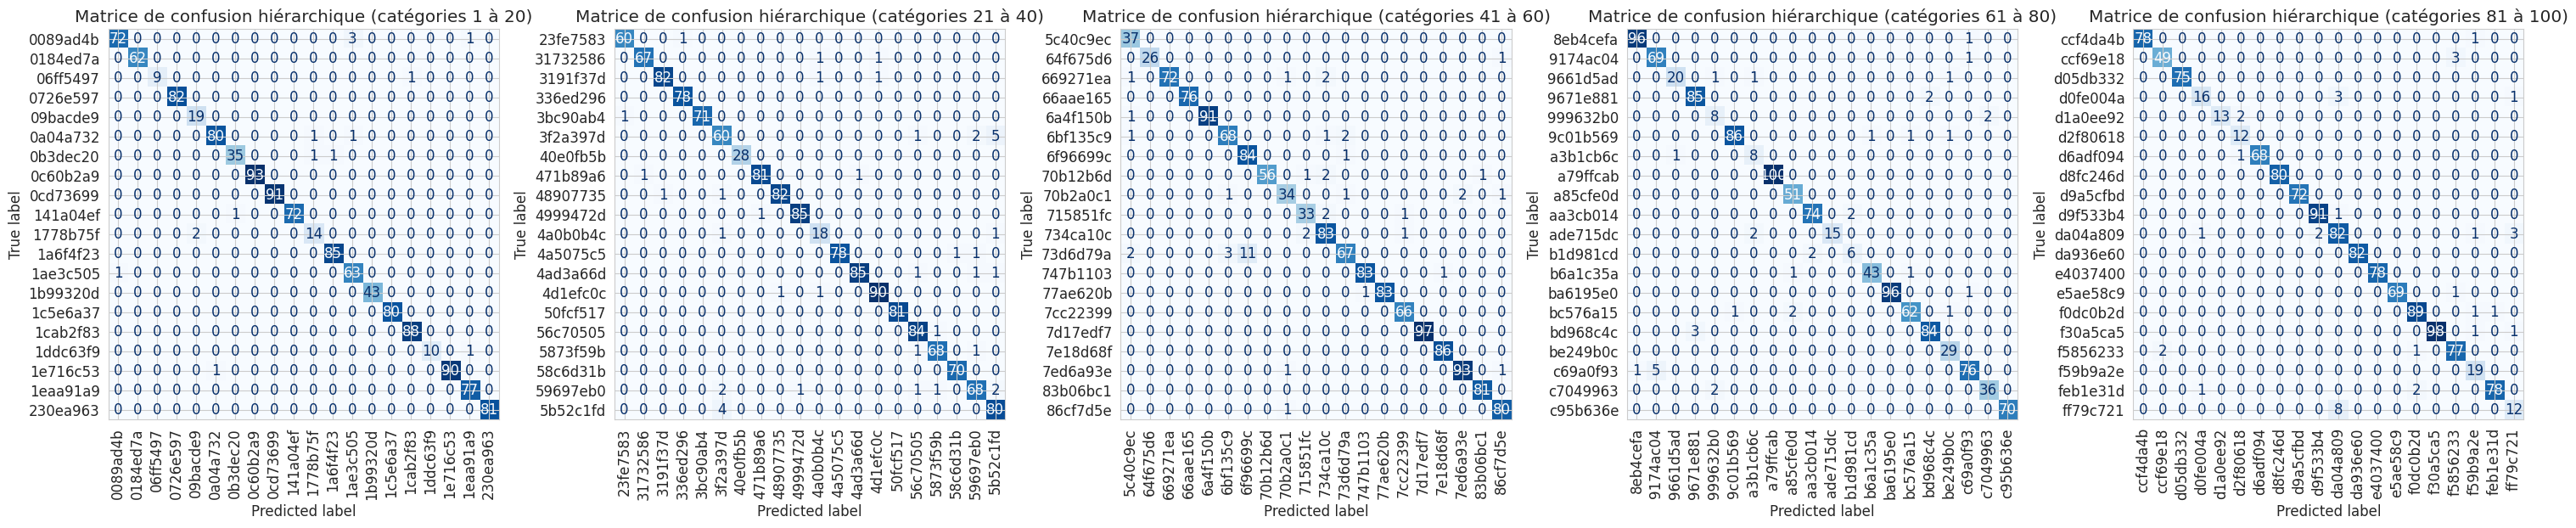

In [ ]:
y_true_hier = testset["category_id"]
y_pred_hier = pred_leaf_ids

y_true_encoded = label_encoder.transform(y_true_hier)
y_pred_encoded = label_encoder.transform(y_pred_hier)

n_classes = len(label_encoder.classes_)
group_size = 20
n_groups = math.ceil(n_classes / group_size)

fig, axes = plt.subplots(1, n_groups, figsize=(6 * n_groups, 16))

if n_groups == 1:
    axes = [axes]

for i in range(n_groups):
    start = i * group_size
    end = min((i + 1) * group_size, n_classes)
    labels_group = list(label_encoder.classes_)[start:end]
    cm_group = confusion_matrix(y_true_encoded, y_pred_encoded, labels=list(range(start, end)))
    disp = ConfusionMatrixDisplay(confusion_matrix=cm_group, display_labels=labels_group)
    disp.plot(ax=axes[i], xticks_rotation=90, cmap="Blues", colorbar=False)
    axes[i].set_title(f"Matrice de confusion hiérarchique (catégories {start+1} à {end})")

plt.tight_layout()
plt.show()

## Comparaison des résultats du modèle hiérarchique

Le modèle hiérarchique simplifié atteint des performances intermédiaires par rapport aux modèles précédents :

- **F1 Macro Test : 0.8058** (vs 0.8002 pour le baseline TF-IDF + Régression Logistique, et 0.8083 pour le modèle flat).
- **F1 Micro Test : 0.8400** (vs 0.8346 pour le baseline, et 0.8418 pour le modèle flat).

Le modèle hiérarchique améliore légèrement le F1 Macro par rapport au baseline (+0.0056), mais reste en dessous du modèle Deep Learning (-0.0025).

Bien que le modèle hiérarchique ait un score légèrement inférieur au modèle flat, il offre un avantage subtil : une fois bien entraîné, il ne peut pas prédire une feuille incohérente avec ses parents. Par exemple, dans un modèle flat, rien n'empêche de prédire "Shampoing" pour un produit classé en "Parfumerie". Le modèle hiérarchique élimine ces incohérences structurelles.

### Pourquoi ces performances modestes ?
Plusieurs facteurs expliquent cette progression limitée :

- **Propagation d'erreurs** : Une erreur au niveau 0 condamne nécessairement les niveaux inférieurs. Cette rigidité peut pénaliser la performance brute.
- **Hiérarchie simplifiée** : Ma simplification à 3 niveaux est arbitraire. La hiérarchie réelle (5.65 niveaux moyens) est plus nuancée.
- **Données limitées** : Pour entraîner efficacement 3 classifieurs, il faudrait plus de données par niveau – ce qui n'est pas le cas pour toutes les classes.


Cette étude exhaustive a été menée dans le cadre d'un environnement de développement avec ressources computationnelles limitées. Plusieurs optimisations potentielles n'ont pu être pleinement explorées :

Entraînement complet : Avec plus de ressources, fait des cross-validation, j'aurais pu ré-entraîner les modèles sur l'ensemble du dataset (sans split validation) après avoir trouvé les hyperparamètres optimaux, Recherche hyperparamétrique approfondie : Grid search systématique pour chaque architecture. Utiliser d'autres feature extractor plus performant comme Roberta original, travailler plus sur la fonction loss et ainsi de suite. A vrai dire cela facile à faire si on a les ressource à disposition, ce n'est pas le plus important dans un premier temps.

L'essentiel a cependant été accompli : une approche méthodologique solide et progressive, allant du modèle simple au complexe et de la classification plate à hiérarchique, a été rigoureusement suivie.

Cette exploration exhaustive a démontré la faisabilité technique et le potentiel business d'un système de classification automatique de produits. Les modèles développés atteignent une performance solide (F1 Macro > 80%) malgré la complexité du problème (100 classes déséquilibrées).

L'approche pragmatique adoptée, allant du modèle simple au complexe, du flat au hiérarchique, permet d'offrir plusieurs options adaptées à différents contextes de déploiement.

Je suis convaincu que ces travaux constituent une base robuste pour une industrialisation réussie, et j'espère qu'ils répondront à vos attentes et j'espère avoir la chance de participer dans vos future projet.